# LAB 07 — Transformer text classification

## Kết quả và đường dẫn nhanh

Đã chạy các phần positional encoding/permutation, số heads, attention diversity, Transformer/LSTM, sequence length, ứng dụng sentiment và pooling. Không cần huấn luyện lại để xuất hình/tổng hợp từ checkpoint và kết quả đã lưu.

| Nội dung | Kết quả chính |
|---|---|
| Các lượt huấn luyện (không đếm lặp checkpoint) | [results.csv](results.csv) |
| Positional encoding minh họa | [positional_encoding.png](images/positional_encoding.png) |
| Attention 4 heads, layer 1, validation index 86 | [attention_heads.png](images/attention_heads.png) |
| Learning curves train/validation | [learning_curves.png](images/learning_curves.png) |
| Confusion matrix trên 25.000 mẫu test | [confusion_matrix.png](images/confusion_matrix.png) |
| Phân tích lỗi và phản tư | [error_analysis.md](error_analysis.md), [reflection.md](reflection.md) |
| Dữ liệu vẽ hình và nguồn kết quả | [artifacts/summary/README.md](artifacts/summary/README.md) |

Các mục khung 1–15 phía dưới được giữ để bảo toàn chỉ số cell mà báo cáo đã trích dẫn; phần triển khai thực tế bắt đầu tại **11. Experiment 1 — Positional encoding** sau khung. CSV/tensor và nguồn từng hình được ghi trong artifacts/summary/README.md; bảng tổng hợp nằm ở mục 13. Output dài ở các cell chi tiết được đặt chế độ cuộn; bảng/hình gốc vẫn được giữ.


## 1. Thiết lập môi trường và reproducibility

In [ ]:
# Xem phần Chuẩn bị chung cho bài 19–22: import, seed và thiết bị.

## 2. Dataset, tokenizer và train/validation/test split

In [ ]:
# Xem phần Chuẩn bị chung cho bài 19–22: IMDb, split cố định và vocab chỉ fit train.

## 3. Bài tập tính toán và shape

In [ ]:
# Xem calculations.md; phần tính tay do sinh viên tự kiểm chứng theo policy.

## 4. Prediction trước thí nghiệm

In [ ]:
# Dự đoán ban đầu nằm trong prediction.md; không sửa theo kết quả thực nghiệm.

## 5. Positional encoding và permutation experiment

In [ ]:
# Xem mục 11. Experiment 1 — Positional encoding và 12. Permutation experiment.

## 6. Transformer Encoder block tự ghép

In [ ]:
# TransformerBlock được triển khai trong transformer_block.py; phần model classifier dùng lại module này.

## 7. Training và evaluation

In [ ]:
# Các hàm train/evaluate ở Chuẩn bị chung cho bài 19–22; checkpoint/kết quả nằm trong artifacts/.

## 8. Số heads và head diversity

In [ ]:
# Xem bài 19 (số heads) và bài 20 (attention diversity).

## 9. So sánh LSTM và Transformer

In [ ]:
# Xem bài 21. Transformer vs LSTM; cùng dữ liệu, split và quy tắc chọn checkpoint.

## 10. Sequence length

In [ ]:
# Xem bài 22. Sequence length; bảng kết quả có trong artifacts/experiments_19_22/.

## 11. Mean pooling và CLS-style pooling

In [ ]:
# Xem bài 25. Pooling strategy; cả hai model cùng có CLS và được train riêng.

## 12. Ứng dụng phân loại cảm xúc

In [ ]:
# Xem bài 23. Application — Transformer text classification.

## 13. Tổng hợp kết quả và biểu đồ

Bốn PNG trong thư mục images/ được xuất từ dữ liệu thật đã lưu. `results.csv` chỉ chứa metric/config tổng hợp; dữ liệu PE, attention, loss từng epoch và confusion matrix được giữ riêng trong `artifacts/summary/`. Nguồn và dữ liệu vẽ hình được ghi tại artifacts/summary/README.md; có thể đọc trực tiếp các dữ liệu đã lưu để vẽ lại mà không train lại.

In [3]:
from pathlib import Path
import pandas as pd
from IPython.display import display

if Path("results.csv").is_file():
    overview = pd.read_csv("results.csv")
    if not overview.empty:
        display(overview[["model", "n_heads", "max_length", "pooling", "accuracy", "f1"]])
    else:
        print("Chạy phần Tổng hợp output cuối notebook để xuất dữ liệu kết quả đã lưu.")


,model,n_heads,max_length,pooling,accuracy,f1
0,Transformer,1.0,128,masked_mean,0.80996,0.809856
1,Transformer,2.0,128,masked_mean,0.80888,0.808625
2,Transformer,4.0,128,masked_mean,0.81088,0.810662
3,Transformer,8.0,128,masked_mean,0.80532,0.804929
4,LSTM,NaN,128,last_hidden,0.64820,0.647774
5,Transformer,4.0,32,masked_mean,0.69352,0.693516
6,Transformer,4.0,64,masked_mean,0.75076,0.750449
7,Transformer,4.0,256,masked_mean,0.83572,0.834886
8,Transformer,4.0,128,Mean,0.80712,0.806885
9,Transformer,4.0,128,CLS-style,0.77988,0.779736


## 14. Error analysis, prediction verification và reflection

In [ ]:
# Báo cáo nằm trong error_analysis.md và reflection.md; không triển khai bài 26/28 trong notebook.

## 15. AI assistance statement

In [ ]:
# AI assistance statement và checklist sinh viên nằm trong mục 30 của reflection.md.

## 11. Experiment 1 — Positional encoding

Mục này chạy độc lập với các cell khung ở trên, không huấn luyện và không dùng dữ liệu bên ngoài. Em so sánh `["I", "love", "NLP"]` và `["NLP", "love", "I"]` với cùng embedding cho mỗi token, cùng trọng số self-attention, `d_model = 4`, `num_heads = 2`, `dropout = 0` và không có attention mask.

Với `pos = 0, 1, 2` và `i = 0, 1`, sinusoidal positional encoding được tính bằng:

$$PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right),\qquad PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right).$$

Hai trường hợp là $X=Embedding$ và $X=Embedding+PE$. Mỗi sequence nhận PE theo **vị trí hiện tại**; PE không bị đảo theo token. Seed cố định, CPU và `float64` giúp tái lập phép minh họa. Chỉ định dạng khi hiển thị, không làm tròn tensor trước khi kiểm tra.

In [1]:
import torch
from torch import nn

SEED = 42
torch.manual_seed(SEED)
torch.set_printoptions(precision=8, sci_mode=False)
d_model, num_heads = 4, 2
dtype = torch.float64
sequences = [["I", "love", "NLP"], ["NLP", "love", "I"]]
vocab = ["I", "love", "NLP"]
token_to_id = {token: i for i, token in enumerate(vocab)}
embedding_matrix = torch.randn(len(vocab), d_model, dtype=dtype, device="cpu")
embeddings = [embedding_matrix[torch.tensor([token_to_id[t] for t in seq])]
              for seq in sequences]
positions = torch.arange(3, dtype=dtype).unsqueeze(1)
even_dimensions = torch.arange(0, d_model, 2, dtype=dtype)
angles = positions / (10000.0 ** (even_dimensions / d_model))
pe = torch.zeros(3, d_model, dtype=dtype)
pe[:, 0::2] = torch.sin(angles)
pe[:, 1::2] = torch.cos(angles)

# Một lớp duy nhất, dùng chung trọng số cho cả bốn lượt chạy.
attention = nn.MultiheadAttention(
    embed_dim=d_model, num_heads=num_heads, dropout=0.0,
    batch_first=True, dtype=dtype, device="cpu"
)
attention.eval()
print("Seed:", SEED)
print("Embedding matrix; thứ tự hàng:", vocab)
print(embedding_matrix)
print("Sinusoidal PE; thứ tự hàng: pos = 0, 1, 2")
print(pe)


Seed: 42
Embedding matrix; thứ tự hàng: ['I', 'love', 'NLP']
tensor([[ 0.33669035,  0.12880941,  0.23446236,  0.23033303],
        [-1.12285638, -0.18632830,  2.20820134, -0.63799706],
        [ 0.46165722,  0.26735087,  0.53490468,  0.80935721]],
       dtype=torch.float64)
Sinusoidal PE; thứ tự hàng: pos = 0, 1, 2
tensor([[ 0.00000000,  1.00000000,  0.00000000,  1.00000000],
        [ 0.84147098,  0.54030231,  0.00999983,  0.99995000],
        [ 0.90929743, -0.41614684,  0.01999867,  0.99980001]],
       dtype=torch.float64)


### Chạy self-attention và hiển thị representation

Mỗi batch chứa hai sequence, có shape `(2, 3, 4)`. Representation từng token là đầu ra của lớp `MultiheadAttention`, bao gồm phép chiếu đầu ra; không thêm residual, feed-forward hay layer normalization. Representation cả sequence là trung bình ba hàng đầu ra. Không có thông tin vị trí nghĩa là phần PE thực sự được cộng bằng 0.

In [2]:
results = {}
with torch.no_grad():
    for case_name, added_pe in [
        ("Không có positional information", torch.zeros_like(pe)),
        ("Có positional information", pe),
    ]:
        x = torch.stack([emb + added_pe for emb in embeddings])
        output, _ = attention(x, x, x, attn_mask=None,
                              key_padding_mask=None, need_weights=False)
        pooled = output.mean(dim=1)
        results[case_name] = {"input": x, "output": output, "pooled": pooled}
        print("\n===", case_name, "===")
        for seq_index, tokens in enumerate(sequences):
            print("\nSequence:", tokens)
            print("Token embeddings (hàng theo thứ tự token):\n", embeddings[seq_index])
            print("Sinusoidal PE tham chiếu (pos = 0, 1, 2):\n", pe)
            print("PE thực sự được cộng:\n", added_pe)
            print("Đầu vào self-attention:\n", x[seq_index])
            print("Representation đầu ra từng token:")
            for token, row in zip(tokens, output[seq_index]):
                print(f"  {token}: {row}")
            print("Representation sequence bằng mean pooling:\n", pooled[seq_index])



=== Không có positional information ===

Sequence: ['I', 'love', 'NLP']
Token embeddings (hàng theo thứ tự token):
 tensor([[ 0.33669035,  0.12880941,  0.23446236,  0.23033303],
        [-1.12285638, -0.18632830,  2.20820134, -0.63799706],
        [ 0.46165722,  0.26735087,  0.53490468,  0.80935721]],
       dtype=torch.float64)
Sinusoidal PE tham chiếu (pos = 0, 1, 2):
 tensor([[ 0.00000000,  1.00000000,  0.00000000,  1.00000000],
        [ 0.84147098,  0.54030231,  0.00999983,  0.99995000],
        [ 0.90929743, -0.41614684,  0.01999867,  0.99980001]],
       dtype=torch.float64)
PE thực sự được cộng:
 tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]], dtype=torch.float64)
Đầu vào self-attention:
 tensor([[ 0.33669035,  0.12880941,  0.23446236,  0.23033303],
        [-1.12285638, -0.18632830,  2.20820134, -0.63799706],
        [ 0.46165722,  0.26735087,  0.53490468,  0.80935721]],
       dtype=torch.float64)
Representation đầu ra từng token:
  I: tensor([

### Kiểm tra bằng số

Phép hoán vị `[2, 1, 0]` biến sequence gốc thành sequence đảo và cũng căn chỉnh sequence đảo về thứ tự token gốc. Không có PE, em kiểm tra cả $Y_{đảo} \approx P Y_{gốc}$ và $P Y_{đảo} \approx Y_{gốc}$. Có PE, em so sánh đầu ra sau khi căn chỉnh theo token và mean pooling, báo cáo sai khác thực tế mà không bắt buộc chúng phải khác nhau.

Mọi so sánh dùng `torch.allclose(atol=1e-6, rtol=1e-5)` và sai khác tuyệt đối lớn nhất trên tensor chưa làm tròn.

In [3]:
ATOL, RTOL = 1e-6, 1e-5
permutation = torch.tensor([2, 1, 0])

def report_comparison(label, a, b):
    is_close = torch.allclose(a, b, atol=ATOL, rtol=RTOL)
    max_diff = (a - b).abs().max().item()
    print(f"{label}: allclose={is_close}; max_abs_diff={max_diff:.12e}")
    return is_close, max_diff

checks = {}
for case_name, tensors in results.items():
    y, pooled = tensors["output"], tensors["pooled"]
    print("\n===", case_name, "===")
    equivariance = report_comparison(
        "Đầu ra sequence đảo so với đầu ra gốc đảo hàng", y[1], y[0, permutation])
    aligned = report_comparison(
        "Đầu ra sequence đảo căn chỉnh theo token so với gốc", y[1, permutation], y[0])
    pooling = report_comparison("Mean pooling hai sequence", pooled[1], pooled[0])
    checks[case_name] = {"equivariance": equivariance,
                         "aligned": aligned, "pooling": pooling}

without_pe = checks["Không có positional information"]
assert without_pe["equivariance"][0], "Kiểm tra permutation equivariance chưa đạt."
assert without_pe["aligned"][0], "Đầu ra theo token sau căn chỉnh chưa khớp."
assert without_pe["pooling"][0], "Mean pooling không PE chưa khớp."

with_pe = checks["Có positional information"]
print("\nNhận xét từ lần chạy với PE:")
for key, label in [("aligned", "Đầu ra sau căn chỉnh theo token"),
                   ("pooling", "Mean pooling")]:
    close, difference = with_pe[key]
    status = "xấp xỉ bằng nhau" if close else "khác nhau theo ngưỡng kiểm tra"
    print(f"{label}: {status}; sai khác lớn nhất = {difference:.12e}.")
print("Kết quả với PE chỉ mô tả embedding và trọng số cố định của lần chạy này;")
print("PE không bảo đảm mọi representation hoặc mean pooling luôn khác nhau.")



=== Không có positional information ===
Đầu ra sequence đảo so với đầu ra gốc đảo hàng: allclose=True; max_abs_diff=5.551115123126e-17
Đầu ra sequence đảo căn chỉnh theo token so với gốc: allclose=True; max_abs_diff=5.551115123126e-17
Mean pooling hai sequence: allclose=True; max_abs_diff=2.081668171172e-17

=== Có positional information ===
Đầu ra sequence đảo so với đầu ra gốc đảo hàng: allclose=False; max_abs_diff=1.431355542048e-01
Đầu ra sequence đảo căn chỉnh theo token so với gốc: allclose=False; max_abs_diff=1.431355542048e-01
Mean pooling hai sequence: allclose=False; max_abs_diff=9.694217739314e-03

Nhận xét từ lần chạy với PE:
Đầu ra sau căn chỉnh theo token: khác nhau theo ngưỡng kiểm tra; sai khác lớn nhất = 1.431355542048e-01.
Mean pooling: khác nhau theo ngưỡng kiểm tra; sai khác lớn nhất = 9.694217739314e-03.
Kết quả với PE chỉ mô tả embedding và trọng số cố định của lần chạy này;
PE không bảo đảm mọi representation hoặc mean pooling luôn khác nhau.


### Nhận xét và trả lời câu hỏi

**Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?**

Self-attention không có thông tin vị trí là **permutation equivariant**: khi đổi thứ tự token, các hàng đầu ra đổi thứ tự tương ứng. Tensor đầu ra có thể đổi cách sắp xếp nhưng mô hình không tự nhận biết quan hệ trước/sau; sau khi căn chỉnh theo token, các representation xấp xỉ bằng nhau như kiểm tra phía trên.

Mean pooling là **permutation invariant**: đổi thứ tự các hàng không làm thay đổi trung bình. Vì vậy, representation sau mean pooling không phân biệt được hai sequence chỉ khác thứ tự trong trường hợp không có thông tin vị trí.

Positional encoding bổ sung vị trí để mô hình **có thể** biểu diễn sự khác biệt về thứ tự. Trong lần chạy này, đầu ra sau căn chỉnh và mean pooling với PE đều khác nhau theo ngưỡng kiểm tra; sai khác thực tế được in ở trên. Kết quả phụ thuộc embedding, trọng số attention và phép tổng hợp, nên PE không bảo đảm mọi representation hoặc mean pooling luôn khác nhau. Đây là phép minh họa với trọng số chưa huấn luyện, không phải đánh giá accuracy.

## 12. Permutation experiment

Em dùng `S1 = ["dog", "bites", "man"]` và `S2 = ["man", "bites", "dog"]` để kiểm tra ảnh hưởng của thông tin vị trí. Mục này chạy độc lập, dùng PyTorch trên CPU, seed cố định, `d_model = 4`, `num_heads = 2`, `float64` và không huấn luyện. Mỗi token có một embedding dùng chung cho cả hai sequence.

Một lớp self-attention duy nhất được dùng cho cả Experiment A và B: cùng trọng số, `dropout = 0`, chế độ `eval`, không attention mask hay padding mask, và tính forward trong `torch.no_grad()`.

- **Experiment A:** $X = Embedding$, không có nguồn thông tin vị trí nào.
- **Experiment B:** $X = Embedding + PE$, với $PE(pos,2i)=\sin(pos/10000^{2i/d_{model}})$ và $PE(pos,2i+1)=\cos(pos/10000^{2i/d_{model}})$, `pos = 0, 1, 2`.

PE được gán theo vị trí hiện tại trong từng sequence, không đảo PE cùng token. Representation từng token là đầu ra lớp attention, không thêm residual hay các lớp khác; representation sequence là mean pooling trên chiều token.

In [1]:
import torch
from torch import nn
from IPython.display import Markdown, display

perm_seed = 42
torch.manual_seed(perm_seed)
torch.set_printoptions(precision=8, sci_mode=False)
perm_d_model, perm_num_heads = 4, 2
perm_dtype = torch.float64
perm_sequences = [["dog", "bites", "man"], ["man", "bites", "dog"]]
perm_vocab = ["dog", "bites", "man"]
perm_token_to_id = {token: i for i, token in enumerate(perm_vocab)}
perm_embedding_matrix = torch.randn(3, perm_d_model, dtype=perm_dtype, device="cpu")
perm_embeddings = torch.stack([
    perm_embedding_matrix[torch.tensor([perm_token_to_id[token] for token in sequence])]
    for sequence in perm_sequences
])
perm_positions = torch.arange(3, dtype=perm_dtype).unsqueeze(1)
perm_even_dims = torch.arange(0, perm_d_model, 2, dtype=perm_dtype)
perm_angles = perm_positions / (10000.0 ** (perm_even_dims / perm_d_model))
perm_pe = torch.zeros(3, perm_d_model, dtype=perm_dtype)
perm_pe[:, 0::2] = torch.sin(perm_angles)
perm_pe[:, 1::2] = torch.cos(perm_angles)

# Chỉ khởi tạo một lần; không thay đổi trọng số giữa A và B.
perm_attention = nn.MultiheadAttention(
    embed_dim=perm_d_model, num_heads=perm_num_heads, dropout=0.0,
    batch_first=True, dtype=perm_dtype, device="cpu"
)
perm_attention.eval()
print("Seed:", perm_seed)
print("Token embeddings; thứ tự hàng:", perm_vocab)
print(perm_embedding_matrix)
print("Sinusoidal positional encoding; các hàng pos = 0, 1, 2:")
print(perm_pe)


Seed: 42
Token embeddings; thứ tự hàng: ['dog', 'bites', 'man']
tensor([[ 0.33669035,  0.12880941,  0.23446236,  0.23033303],
        [-1.12285638, -0.18632830,  2.20820134, -0.63799706],
        [ 0.46165722,  0.26735087,  0.53490468,  0.80935721]],
       dtype=torch.float64)
Sinusoidal positional encoding; các hàng pos = 0, 1, 2:
tensor([[ 0.00000000,  1.00000000,  0.00000000,  1.00000000],
        [ 0.84147098,  0.54030231,  0.00999983,  0.99995000],
        [ 0.90929743, -0.41614684,  0.01999867,  0.99980001]],
       dtype=torch.float64)


### Forward và representation của từng sequence

Mỗi lần forward xử lý batch gồm S1 và S2. Cell dưới hiển thị token embeddings, phần PE thực sự được cộng, đầu vào attention, đầu ra từng token và mean pooling cho cả hai experiment. Các tensor chỉ được định dạng khi in, không làm tròn giá trị dùng trong tính toán.

In [2]:
perm_results = {}
with torch.no_grad():
    for perm_name, perm_added_pe in [
        ("A — Không PE", torch.zeros_like(perm_pe)),
        ("B — Có PE", perm_pe),
    ]:
        # Broadcast cùng bảng PE theo vị trí hiện tại cho cả hai sequence.
        perm_x = perm_embeddings + perm_added_pe.unsqueeze(0)
        perm_y, _ = perm_attention(
            perm_x, perm_x, perm_x, attn_mask=None,
            key_padding_mask=None, need_weights=False
        )
        perm_pooled = perm_y.mean(dim=1)
        perm_results[perm_name] = {"input": perm_x, "output": perm_y,
                                   "pooled": perm_pooled}
        print("\n=== Experiment", perm_name, "===")
        for perm_index, perm_tokens in enumerate(perm_sequences):
            print(f"\nS{perm_index + 1} = {perm_tokens}")
            print("Token embeddings:\n", perm_embeddings[perm_index])
            print("PE thực sự được cộng (hàng theo vị trí hiện tại):\n", perm_added_pe)
            print("Đầu vào self-attention:\n", perm_x[perm_index])
            print("Representation đầu ra theo token:")
            for perm_token, perm_row in zip(perm_tokens, perm_y[perm_index]):
                print(f"  {perm_token}: {perm_row}")
            print("Vector mean pooling:\n", perm_pooled[perm_index])



=== Experiment A — Không PE ===

S1 = ['dog', 'bites', 'man']
Token embeddings:
 tensor([[ 0.33669035,  0.12880941,  0.23446236,  0.23033303],
        [-1.12285638, -0.18632830,  2.20820134, -0.63799706],
        [ 0.46165722,  0.26735087,  0.53490468,  0.80935721]],
       dtype=torch.float64)
PE thực sự được cộng (hàng theo vị trí hiện tại):
 tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]], dtype=torch.float64)
Đầu vào self-attention:
 tensor([[ 0.33669035,  0.12880941,  0.23446236,  0.23033303],
        [-1.12285638, -0.18632830,  2.20820134, -0.63799706],
        [ 0.46165722,  0.26735087,  0.53490468,  0.80935721]],
       dtype=torch.float64)
Representation đầu ra theo token:
  dog: tensor([ 0.04381696, -0.02887045, -0.00233284,  0.06183741],
       dtype=torch.float64)
  bites: tensor([ 0.06329531, -0.05612977,  0.01592509, -0.02541150],
       dtype=torch.float64)
  man: tensor([ 0.05172483, -0.03689821,  0.00381172,  0.03208308],
       dtype=tor

### Căn chỉnh và bảng tổng hợp

Dùng `[2, 1, 0]` để đưa các hàng đầu ra S2 về thứ tự token S1, rồi so sánh với đầu ra S1. Mean pooling được so sánh trực tiếp. Mỗi phép so sánh dùng `torch.allclose(atol=1e-6, rtol=1e-5)` trên tensor gốc và báo cáo sai khác tuyệt đối lớn nhất. Chỉ Experiment A có assertion về tính tương đương; Experiment B báo cáo kết quả thực tế, không ép buộc hai representation phải khác nhau.

In [3]:
perm_atol, perm_rtol = 1e-6, 1e-5
perm_alignment = torch.tensor([2, 1, 0])
perm_checks = {}
perm_table = [
    "| Experiment | Max abs diff đầu ra đã căn chỉnh | Allclose theo token | Max abs diff mean pooling | Allclose mean pooling |",
    "|---|---:|:---:|---:|:---:|",
]
for perm_name, perm_tensors in perm_results.items():
    perm_reference = perm_tensors["output"][0]
    perm_aligned = perm_tensors["output"][1, perm_alignment]
    perm_pool_s1, perm_pool_s2 = perm_tensors["pooled"].unbind(0)
    perm_token_diff = (perm_aligned - perm_reference).abs().max().item()
    perm_pool_diff = (perm_pool_s2 - perm_pool_s1).abs().max().item()
    perm_token_close = torch.allclose(perm_aligned, perm_reference,
                                      atol=perm_atol, rtol=perm_rtol)
    perm_pool_close = torch.allclose(perm_pool_s2, perm_pool_s1,
                                     atol=perm_atol, rtol=perm_rtol)
    perm_checks[perm_name] = {"token_diff": perm_token_diff,
                              "token_close": perm_token_close,
                              "pool_diff": perm_pool_diff,
                              "pool_close": perm_pool_close}
    print("\nExperiment", perm_name)
    print("Đầu ra S2 đã căn chỉnh theo token S1:\n", perm_aligned)
    perm_table.append(
        f"| {perm_name} | {perm_token_diff:.12e} | {perm_token_close} "
        f"| {perm_pool_diff:.12e} | {perm_pool_close} |"
    )

assert perm_checks["A — Không PE"]["token_close"], "A: đầu ra căn chỉnh chưa khớp."
assert perm_checks["A — Không PE"]["pool_close"], "A: mean pooling chưa khớp."
display(Markdown("\n".join(perm_table)))

perm_observations = ["**Nhận xét từ số liệu thực tế:**"]
for perm_name, perm_values in perm_checks.items():
    perm_token_status = "xấp xỉ bằng nhau" if perm_values["token_close"] else "khác nhau theo ngưỡng kiểm tra"
    perm_pool_status = "xấp xỉ bằng nhau" if perm_values["pool_close"] else "khác nhau theo ngưỡng kiểm tra"
    perm_observations.append(
        f"- Experiment {perm_name}: đầu ra sau căn chỉnh {perm_token_status} "
        f"(max abs diff = {perm_values['token_diff']:.12e}); mean pooling "
        f"{perm_pool_status} (max abs diff = {perm_values['pool_diff']:.12e})."
    )
display(Markdown("\n\n".join(perm_observations)))



Experiment A — Không PE
Đầu ra S2 đã căn chỉnh theo token S1:
 tensor([[ 0.04381696, -0.02887045, -0.00233284,  0.06183741],
        [ 0.06329531, -0.05612977,  0.01592509, -0.02541150],
        [ 0.05172483, -0.03689821,  0.00381172,  0.03208308]],
       dtype=torch.float64)

Experiment B — Có PE
Đầu ra S2 đã căn chỉnh theo token S1:
 tensor([[ 0.45353761, -0.17337764,  0.12454415, -0.66188616],
        [ 0.47906405, -0.16999346,  0.16795289, -0.75984458],
        [ 0.49912414, -0.17994187,  0.18283789, -0.81373801]],
       dtype=torch.float64)


| Experiment | Max abs diff đầu ra đã căn chỉnh | Allclose theo token | Max abs diff mean pooling | Allclose mean pooling |
|---|---:|:---:|---:|:---:|
| A — Không PE | 5.551115123126e-17 | True | 2.081668171172e-17 | True |
| B — Có PE | 1.431355542048e-01 | False | 9.694217739314e-03 | False |

**Nhận xét từ số liệu thực tế:**

- Experiment A — Không PE: đầu ra sau căn chỉnh xấp xỉ bằng nhau (max abs diff = 5.551115123126e-17); mean pooling xấp xỉ bằng nhau (max abs diff = 2.081668171172e-17).

- Experiment B — Có PE: đầu ra sau căn chỉnh khác nhau theo ngưỡng kiểm tra (max abs diff = 1.431355542048e-01); mean pooling khác nhau theo ngưỡng kiểm tra (max abs diff = 9.694217739314e-03).

### Nhận xét và phạm vi kết luận

Các sai khác và kết quả `allclose` ở bảng trên được tính từ lần chạy thực tế. Trong Experiment A, đầu ra S2 sau căn chỉnh xấp xỉ bằng đầu ra S1: self-attention không có positional information là **permutation equivariant**, tức đảo token làm các hàng đầu ra đảo tương ứng. Cách sắp xếp các hàng thay đổi không có nghĩa attention tự nhận biết được quan hệ trước/sau.

Mean pooling là **permutation invariant**, nên Experiment A cho cùng representation sequence về mặt toán học; sai khác rất nhỏ khi chạy là sai số số học và nằm trong ngưỡng kiểm tra. Vì vậy, bước pooling này không phân biệt được hai sequence chỉ khác thứ tự.

Trong Experiment B, PE bổ sung vị trí cho từng token và cho phép đầu ra phụ thuộc vào thứ tự. Bảng và nhận xét được sinh trực tiếp từ tensor ở trên cho biết mức sai khác thực tế của lần chạy này. Không thể suy rộng rằng mọi trọng số attention hoặc mọi cách pooling đều chắc chắn tạo representation khác nhau khi có PE.

**Khả năng biểu diễn thứ tự khác với khả năng hiểu đúng nghĩa.** Thí nghiệm không huấn luyện này chưa chứng minh mô hình hiểu ai cắn ai trong “dog bites man” và “man bites dog”.

Kết luận về tính hoán vị ở đây áp dụng cho self-attention không có mask mang thông tin thứ tự hoặc bất kỳ nguồn thông tin vị trí nào khác. Positional encoding là một cách cung cấp thông tin vị trí cho mô hình.

## Chuẩn bị chung cho bài 19–22

**Dataset:** đọc đúng Arrow cache `stanfordnlp/imdb` mà `../lab05/sequence_classification.ipynb` sử dụng. Tái lập split cell 12/21 của LAB 05: `random_split` 80/20 từ train chính thức, generator seed 42 → 20.000 train, 5.000 validation; giữ 25.000 test chính thức. Vocabulary chỉ fit trên 20.000 train; tokenizer `text.lower().split()` như LAB 05; nhãn 0=negative, 1=positive.

**Cấu hình đặt trước khi chạy:** seed 42; embedding ngẫu nhiên có học, chiều 128; một block tự triển khai, FFN 512, dropout residual 0.1, sinusoidal PE và masked mean pooling. Adam, LR 0.001, CrossEntropyLoss, 3 epochs, batch 64; max_length chuẩn 128. LSTM: hidden 128, một layer một hướng, packed sequence, dropout đầu ra 0.1. Dùng float32, không AMP, fixed padding đến max_length. Không giảm batch khi OOM.

**Checkpoint:** validation macro F1 cao nhất, nếu hòa chọn validation loss thấp hơn, rồi epoch sớm hơn. Test chỉ đánh giá sau khi chọn; không dùng test để chọn cấu hình. Metrics: accuracy và macro Precision/Recall/F1, labels=[0,1], zero_division=0.

**Training time:** `perf_counter`, đồng bộ CUDA trước/sau, từ trước epoch đầu tới sau epoch cuối; gồm train, validation mỗi epoch, sao chép best state về CPU và logging. Không gồm tokenization, tạo model/loader/optimizer, lưu checkpoint, test hoặc vẽ. Dùng cùng cách đo cho mọi cấu hình.

Artifacts lưu tại `artifacts/experiments_19_22/`. Chỉ tái sử dụng khi khớp fingerprint dữ liệu/split/vocab, mã mô hình/core, cấu hình, protocol, thiết bị và phiên bản PyTorch. Đây là kết quả một seed, chưa đo biến thiên giữa các seed.

**Giới hạn thời gian:** không warm-up riêng trước khoảng đo. Lượt đầu (1 head) có thể bao gồm chi phí khởi tạo/lazy initialization của CUDA. Bảng thời gian là phép đo theo protocol này, không đủ kết luận 1 head vốn chậm hơn các cấu hình khác; cần benchmark warm-up và nhiều lần lặp để so sánh tốc độ ổn định.

In [1]:
import copy, hashlib, inspect, json, math, random, platform
from pathlib import Path
from collections import Counter
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset, random_split
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display, Markdown
from transformer_block import TransformerBlock

EX_SEED = 42
EX_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EX_DIR = Path("artifacts/experiments_19_22")
EX_DIR.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

def ex_seed():
    random.seed(EX_SEED); np.random.seed(EX_SEED); torch.manual_seed(EX_SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(EX_SEED)

def ex_sync():
    if EX_DEVICE.type == "cuda": torch.cuda.synchronize()

def ex_hash_file(path):
    digest = hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b""): digest.update(chunk)
    return digest.hexdigest()

ex_seed()
print("Thiết bị:", EX_DEVICE, "; PyTorch:", torch.__version__)
print("CPU:", platform.processor(), "; CPU threads:", torch.get_num_threads(), "; dtype: float32")
if EX_DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), "; VRAM GiB:", torch.cuda.get_device_properties(0).total_memory/2**30)
# Đọc Arrow tại chỗ, không tải mạng hoặc ghi vào cache bên ngoài workspace.
ex_cache = Path.home()/".cache/huggingface/datasets/stanfordnlp___imdb"
ex_candidates = sorted(ex_cache.rglob("imdb-train.arrow"))
if not ex_candidates:
    raise FileNotFoundError("Cần cung cấp vị trí dữ liệu IMDb của LAB 05.")
ex_train_path = ex_candidates[-1]
ex_test_path = ex_train_path.with_name("imdb-test.arrow")
ex_raw_train = Dataset.from_file(str(ex_train_path))
ex_raw_test = Dataset.from_file(str(ex_test_path))
assert len(ex_raw_train) == len(ex_raw_test) == 25000
ex_tr, ex_va = random_split(range(25000), [20000,5000], generator=torch.Generator().manual_seed(42))
ex_indices = {"train": ex_tr.indices, "validation": ex_va.indices, "test": list(range(25000))}
ex_all_texts, ex_all_labels = list(ex_raw_train["text"]), list(ex_raw_train["label"])
ex_texts = {name: [ex_all_texts[i] for i in ex_indices[name]] for name in ["train","validation"]}
ex_labels = {name: [int(ex_all_labels[i]) for i in ex_indices[name]] for name in ["train","validation"]}
ex_texts["test"] = list(ex_raw_test["text"])
ex_labels["test"] = [int(y) for y in ex_raw_test["label"]]
ex_tokens = {name: [text.lower().split() for text in rows] for name,rows in ex_texts.items()}
ex_counts = Counter(token for row in ex_tokens["train"] for token in row)
ex_vocab = {"<PAD>":0,"<UNK>":1}
ex_vocab.update({word:i+2 for i,(word,_) in enumerate(ex_counts.most_common(9998))})
assert len(ex_vocab) == 10000
ex_encoded = {name:[[ex_vocab.get(t,1) for t in row] for row in rows] for name,rows in ex_tokens.items()}
assert all(len(row)>0 for rows in ex_encoded.values() for row in rows)
ex_protocol = {"dataset":"stanfordnlp/imdb", "train_sha256":ex_hash_file(ex_train_path),
               "test_sha256":ex_hash_file(ex_test_path), "indices":ex_indices,
               "vocabulary":ex_vocab,"tokenizer":"lower().split()","seed":42}
ex_data_hash = hashlib.sha256(json.dumps(ex_protocol,sort_keys=True).encode()).hexdigest()
(EX_DIR/"data_protocol.json").write_text(json.dumps(ex_protocol,ensure_ascii=False),encoding="utf-8")
print("Nguồn:",ex_train_path.parent,"\nData fingerprint:",ex_data_hash)
display(pd.DataFrame([{"Split":name,"Samples":len(rows),"Negative":ex_labels[name].count(0),
    "Positive":ex_labels[name].count(1),"Tokens before truncation":sum(map(len,rows))}
    for name,rows in ex_tokens.items()]))

# Đường dẫn hình tập trung; giữ nguyên cấu hình và protocol train.
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

def save_lab_figure(name):
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / Path(name).name, dpi=150, bbox_inches="tight")
    plt.show()


Thiết bị: cuda ; PyTorch: 2.14.0+cu132
CPU: Intel64 Family 6 Model 198 Stepping 2, GenuineIntel ; CPU threads: 4 ; dtype: float32
NVIDIA GeForce RTX 5060 Ti ; VRAM GiB: 15.90179443359375


Nguồn: C:\Users\tasdus_117\.cache\huggingface\datasets\stanfordnlp___imdb\plain_text\0.0.0\e6281661ce1c48d982bc483cf8a173c1bbeb5d31 
Data fingerprint: 4cdaa0e3393ccbfacbfd1d6d8841dbced9d8dad457e3c2d64ff13cf8981a93f9


,Split,Samples,Negative,Positive,Tokens before truncation
0,train,20000,9987,10013,4664701
1,validation,5000,2513,2487,1179979
2,test,25000,12500,12500,5713167


### Mô hình và xử lý padding

Mask True tại PAD loại key padding khỏi attention; query padding được đưa về 0. Masked mean pooling chỉ tổng hợp token hợp lệ. LSTM dùng `pack_padded_sequence`. Core tiếp tục dùng Q/K/V tự ghép; `block(x)` vẫn trả tensor, còn `padding_mask`/`return_attention` là tùy chọn mới.

Kiểm tra nhỏ dưới đây xác nhận padding không làm thay đổi logits, attention tới key PAD bằng 0 và packed LSTM giữ đúng trạng thái cuối.

In [2]:
class ExSinusoidalPE(nn.Module):
    def __init__(self,d_model=128,max_length=256):
        super().__init__()
        pos = torch.arange(max_length,dtype=torch.float32).unsqueeze(1)
        angles = pos/(10000.0**(torch.arange(0,d_model,2)/d_model))
        pe = torch.zeros(max_length,d_model)
        pe[:,0::2],pe[:,1::2] = torch.sin(angles),torch.cos(angles)
        self.register_buffer("pe",pe.unsqueeze(0))
    def forward(self,x): return x+self.pe[:,:x.size(1)]

class ExTransformerClassifier(nn.Module):
    def __init__(self,heads):
        super().__init__()
        self.embedding = nn.Embedding(len(ex_vocab),128,padding_idx=0)
        self.position = ExSinusoidalPE()
        self.blocks = nn.ModuleList([TransformerBlock(128,heads,512)])
        self.classifier = nn.Linear(128,2)
    def forward(self,ids,padding_mask,return_attention=False):
        x = self.position(self.embedding(ids))
        weights = []
        for block in self.blocks:
            if return_attention:
                x,w = block(x,padding_mask=padding_mask,return_attention=True)
                weights.append(w)
            else: x = block(x,padding_mask=padding_mask)
        valid = (~padding_mask).unsqueeze(-1)
        pooled = (x*valid).sum(1)/valid.sum(1).clamp_min(1)
        logits = self.classifier(pooled)
        return (logits,weights) if return_attention else logits

class ExLSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(ex_vocab),128,padding_idx=0)
        self.lstm = nn.LSTM(128,128,num_layers=1,batch_first=True,bidirectional=False)
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(128,2)
    def forward(self,ids,padding_mask):
        lengths = (~padding_mask).sum(1).cpu()
        packed = pack_padded_sequence(self.embedding(ids),lengths,batch_first=True,enforce_sorted=False)
        _,(hidden,_) = self.lstm(packed)
        return self.classifier(self.dropout(hidden[-1]))

ex_seed()
probe = ExTransformerClassifier(4).eval()
probe_ids = torch.tensor([[2,3,4,0,0],[5,6,0,0,0]])
probe_mask = probe_ids.eq(0)
with torch.no_grad():
    logits,weights = probe(probe_ids,probe_mask,True)
    assert torch.allclose(logits,probe(probe_ids.masked_fill(probe_mask,7),probe_mask),atol=1e-6,rtol=1e-5)
    for w in weights: assert (w.masked_select(probe_mask[:,None,None,:])==0).all()
    assert torch.allclose(logits[:1],probe(probe_ids[:1,:3],probe_mask[:1,:3]),atol=1e-6,rtol=1e-5)
    lstm_probe = ExLSTMClassifier().eval()
    assert torch.allclose(lstm_probe(probe_ids,probe_mask)[:1],
        lstm_probe(probe_ids[:1,:3],probe_mask[:1,:3]),atol=1e-6,rtol=1e-5)
print("PASS: attention/pooling loại PAD; packed LSTM không bị padding làm sai trạng thái cuối.")
del probe,lstm_probe
EX_BASE = {"seed":42,"d_model":128,"blocks":1,"d_ff":512,"dropout":0.1,
    "pooling":"masked_mean","position":"sinusoidal","max_length":128,"batch_size":64,
    "optimizer":"Adam","lr":0.001,"epochs":3,"loss":"CrossEntropyLoss","dtype":"float32",
    "padding":"fixed","checkpoint":"max val macro F1, min val loss, earliest",
    "lstm_hidden":128,"lstm_layers":1,"lstm_bidirectional":False}
print(json.dumps(EX_BASE,indent=2))


PASS: attention/pooling loại PAD; packed LSTM không bị padding làm sai trạng thái cuối.
{
  "seed": 42,
  "d_model": 128,
  "blocks": 1,
  "d_ff": 512,
  "dropout": 0.1,
  "pooling": "masked_mean",
  "position": "sinusoidal",
  "max_length": 128,
  "batch_size": 64,
  "optimizer": "Adam",
  "lr": 0.001,
  "epochs": 3,
  "loss": "CrossEntropyLoss",
  "dtype": "float32",
  "padding": "fixed",
  "checkpoint": "max val macro F1, min val loss, earliest",
  "lstm_hidden": 128,
  "lstm_layers": 1,
  "lstm_bidirectional": false
}


In [3]:
def ex_make_loaders(config):
    loaders = {}
    length = config["max_length"]
    for name,rows in ex_encoded.items():
        ids = torch.zeros(len(rows),length,dtype=torch.long)
        for i,row in enumerate(rows):
            kept = row[:length]
            ids[i,:len(kept)] = torch.tensor(kept,dtype=torch.long)
        dataset = TensorDataset(ids,torch.tensor(ex_labels[name],dtype=torch.long))
        loaders[name] = DataLoader(dataset,batch_size=config["batch_size"],shuffle=(name=="train"),
            num_workers=0,generator=torch.Generator().manual_seed(42),pin_memory=(EX_DEVICE.type=="cuda"))
    return loaders

def ex_metrics(labels,predictions):
    p,r,f,_ = precision_recall_fscore_support(labels,predictions,labels=[0,1],average="macro",zero_division=0)
    return {"accuracy":float(accuracy_score(labels,predictions)),"precision":float(p),"recall":float(r),"f1":float(f)}

@torch.no_grad()
def ex_evaluate(model,loader):
    model.eval()
    total,count,labels,predictions = 0.0,0,[],[]
    for ids,target in loader:
        ids,target = ids.to(EX_DEVICE),target.to(EX_DEVICE)
        logits = model(ids,ids.eq(0))
        total += nn.functional.cross_entropy(logits,target,reduction="sum").item()
        count += target.size(0)
        labels.extend(target.cpu().tolist()); predictions.extend(logits.argmax(-1).cpu().tolist())
    return {"loss":total/count,**ex_metrics(labels,predictions)}

EX_CORE_HASH = ex_hash_file(Path("transformer_block.py"))
# Hash source của cả mô hình và protocol train/đánh giá; không hash output notebook.
ex_source_cells = json.loads(Path("transformer_classification.ipynb").read_text(encoding="utf-8"))["cells"]
ex_sources = ["".join(c["source"]) if isinstance(c["source"],list) else c["source"]
              for c in ex_source_cells if c["cell_type"]=="code"]
EX_MODEL_HASH = hashlib.sha256("\n".join(s for s in ex_sources if
    s.startswith("class ExSinusoidalPE") or s.startswith("def ex_make_loaders")).encode()).hexdigest()
EX_RUN_VERSION = "19-22-v1-full-imdb-fixed-padding"
ex_runs = {}

def ex_run(model_type="Transformer",heads=4,max_length=128):
    config = {**EX_BASE,"model":model_type,"heads":heads,"max_length":max_length,
        "data_hash":ex_data_hash,"core_hash":EX_CORE_HASH,"model_hash":EX_MODEL_HASH,
        "run_version":EX_RUN_VERSION,"torch":str(torch.__version__),"device":str(EX_DEVICE),
        "device_name":torch.cuda.get_device_name(0) if EX_DEVICE.type=="cuda" else platform.processor()}
    key = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
    checkpoint_path = EX_DIR/f"{model_type.lower()}_h{heads}_t{max_length}_{key[:12]}.pt"
    if key in ex_runs:
        print("Tái sử dụng kết quả trong phiên:",checkpoint_path.name,flush=True)
        return ex_runs[key]
    ex_seed()
    model = (ExTransformerClassifier(heads) if model_type=="Transformer" else ExLSTMClassifier()).to(EX_DEVICE)
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    loaders = ex_make_loaders(config)
    if checkpoint_path.exists():
        cached = torch.load(checkpoint_path,map_location="cpu",weights_only=True)
        if cached["config"]!=config: raise ValueError("Checkpoint không khớp cấu hình")
        model.load_state_dict(cached["state_dict"])
        result = cached["result"]
        assert result["parameters"]==parameters
        print("Tái sử dụng checkpoint khớp cấu hình:",checkpoint_path.name,flush=True)
    else:
        optimizer = torch.optim.Adam(model.parameters(),lr=config["lr"])
        criterion = nn.CrossEntropyLoss()
        history,best_state,best_score,best_epoch = [],None,(-1.0,-float("inf")),None
        print(f"Bắt đầu {model_type}, heads={heads}, length={max_length}, parameters={parameters}",flush=True)
        try:
            ex_sync(); start = perf_counter()
            for epoch in range(1,config["epochs"]+1):
                model.train()
                total,count,labels,predictions = 0.0,0,[],[]
                for ids,target in loaders["train"]:
                    ids,target = ids.to(EX_DEVICE),target.to(EX_DEVICE)
                    optimizer.zero_grad(set_to_none=True)
                    logits = model(ids,ids.eq(0))
                    loss = criterion(logits,target)
                    if not torch.isfinite(loss): raise FloatingPointError("Loss không hữu hạn")
                    loss.backward(); optimizer.step()
                    total += loss.item()*target.size(0); count += target.size(0)
                    labels.extend(target.detach().cpu().tolist())
                    predictions.extend(logits.detach().argmax(-1).cpu().tolist())
                val = ex_evaluate(model,loaders["validation"])
                train = {"loss":total/count,**ex_metrics(labels,predictions)}
                history.append({"epoch":epoch,**{f"train_{k}":v for k,v in train.items()},
                                **{f"val_{k}":v for k,v in val.items()}})
                score = (val["f1"],-val["loss"])
                if score>best_score:
                    best_score,best_epoch = score,epoch
                    best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
                print(f"  epoch={epoch}: train_loss={train['loss']:.4f}, val_loss={val['loss']:.4f}, val_F1={val['f1']:.4f}",flush=True)
            ex_sync(); training_seconds = perf_counter()-start
        except torch.OutOfMemoryError as error:
            (EX_DIR/f"oom_{key[:12]}.json").write_text(json.dumps(
                {"status":"OOM","config":config,"error":str(error)},indent=2),encoding="utf-8")
            raise RuntimeError(f"OOM: {model_type}, heads={heads}, length={max_length}; giữ batch 64.") from error
        model.load_state_dict(best_state)
        test = ex_evaluate(model,loaders["test"])
        result = {"config":config,"parameters":parameters,"training_time":training_seconds,
            "best_epoch":best_epoch,"best_val_f1":best_score[0],"test":test,"history":history,
            "checkpoint":str(checkpoint_path)}
        torch.save({"config":config,"state_dict":best_state,"result":result},checkpoint_path)
        checkpoint_path.with_suffix(".json").write_text(json.dumps(result,indent=2),encoding="utf-8")
    ex_runs[key] = result
    print(f"Hoàn tất: best epoch={result['best_epoch']}; test F1={result['test']['f1']:.4f}; time={result['training_time']:.2f}s",flush=True)
    del model,loaders
    if EX_DEVICE.type=="cuda": torch.cuda.empty_cache()
    return result

def ex_load_model(result):
    config = result["config"]
    model = (ExTransformerClassifier(config["heads"]) if config["model"]=="Transformer" else ExLSTMClassifier()).to(EX_DEVICE)
    checkpoint = torch.load(result["checkpoint"],map_location="cpu",weights_only=True)
    assert checkpoint["config"]==config
    model.load_state_dict(checkpoint["state_dict"])
    return model.eval()

def ex_save_figure(name):
    plt.tight_layout(); plt.savefig(EX_DIR/name,dpi=150,bbox_inches="tight"); plt.show()


## 19. Experiment 2 — Number of attention heads

Giữ cấu hình chuẩn, chỉ thay heads = 1, 2, 4, 8; đặt lại seed, tạo model/optimizer mới cho mỗi lượt. Metrics trong bảng là test của checkpoint được validation chọn. Thời gian của kết quả tái sử dụng là thời gian huấn luyện gốc. Kết quả JSON/CSV lưu thêm macro Precision/Recall và best epoch.

**Nhận xét số liệu:** F1 của 1/2/4/8 heads lần lượt 0.8099/0.8086/0.8107/0.8049; cả accuracy và F1 đều không tăng đều. Tất cả classifier có 1.478.530 tham số trainable, riêng attention có 66.048 tham số, phù hợp chiều concatenation cố định 128.

Bắt đầu Transformer, heads=1, length=128, parameters=1478530


  epoch=1: train_loss=0.5787, val_loss=0.4950, val_F1=0.7618


  epoch=2: train_loss=0.4322, val_loss=0.4586, val_F1=0.7885


  epoch=3: train_loss=0.3522, val_loss=0.4209, val_F1=0.8119


Hoàn tất: best epoch=3; test F1=0.8099; time=19.88s


Bắt đầu Transformer, heads=2, length=128, parameters=1478530


... (11 outputs left out)

  epoch=2: train_loss=0.4204, val_loss=0.4470, val_F1=0.7862


  epoch=3: train_loss=0.3429, val_loss=0.4281, val_F1=0.8027


Hoàn tất: best epoch=3; test F1=0.8049; time=6.75s


,Heads,d_k,Parameters,Training time (s),Accuracy,Macro F1
0,1,128,1478530,19.880371,0.80996,0.809856
1,2,64,1478530,4.045202,0.80888,0.808625
2,4,32,1478530,4.193166,0.81088,0.810662
3,8,16,1478530,6.749123,0.80532,0.804929


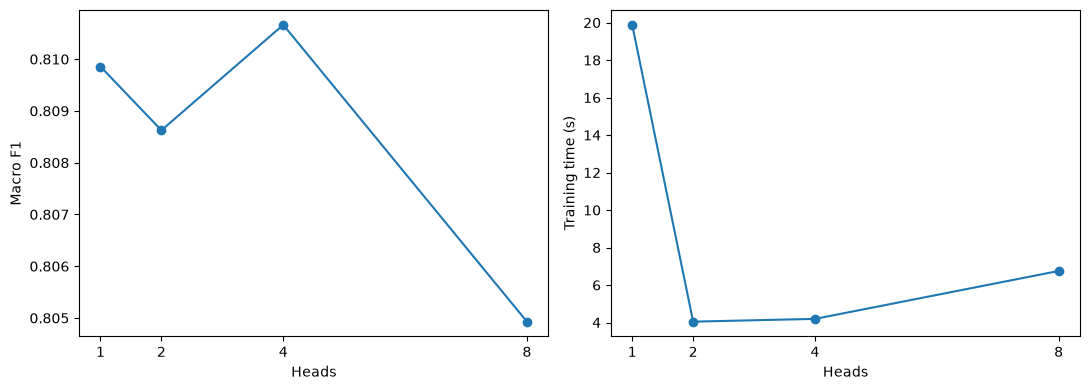

Số tham số attention thực tế: {1: 66048, 2: 66048, 4: 66048, 8: 66048}


1. Tăng heads **không tăng representation dimension**: concatenation vẫn có chiều 128.

2. **d_k = 128 / heads**, lần lượt 128, 64, 32, 16. Dense Q/K/V/output giữ nguyên kích thước; số tham số attention đo được là [66048]; tổng số tham số classifier có 1 giá trị khác nhau.

3. Với seed này, accuracy không giảm theo heads: **False**; macro F1 không giảm: **False**. Đối chiếu bảng và biểu đồ; một seed chưa chứng minh xu hướng tổng quát.

In [4]:
ex_head_runs = {h:ex_run(heads=h) for h in [1,2,4,8]}
ex_head_table = pd.DataFrame([
    {"Heads":h,"d_k":128//h,"Parameters":r["parameters"],"Training time (s)":r["training_time"],
     "Accuracy":r["test"]["accuracy"],"Macro F1":r["test"]["f1"],
     "Macro Precision":r["test"]["precision"],"Macro Recall":r["test"]["recall"],"Best epoch":r["best_epoch"]}
    for h,r in ex_head_runs.items()])
display(ex_head_table[["Heads","d_k","Parameters","Training time (s)","Accuracy","Macro F1"]])
ex_head_table.to_csv(EX_DIR/"heads_results.csv",index=False)
fig,axes = plt.subplots(1,2,figsize=(11,4))
for ax,col in zip(axes,["Macro F1","Training time (s)"]):
    ax.plot(ex_head_table["Heads"],ex_head_table[col],"o-")
    ax.set(xlabel="Heads",ylabel=col,xticks=[1,2,4,8])
save_lab_figure("heads_f1_time.png")
ex_attention_params = {}
for h in [1,2,4,8]:
    probe = ExTransformerClassifier(h)
    ex_attention_params[h] = sum(p.numel() for p in probe.blocks[0].attention.parameters() if p.requires_grad)
print("Số tham số attention thực tế:",ex_attention_params)
ex_acc_up = bool(np.all(np.diff(ex_head_table["Accuracy"])>=0))
ex_f1_up = bool(np.all(np.diff(ex_head_table["Macro F1"])>=0))
display(Markdown(
    "1. Tăng heads **không tăng representation dimension**: concatenation vẫn có chiều 128.\n\n"
    "2. **d_k = 128 / heads**, lần lượt 128, 64, 32, 16. Dense Q/K/V/output giữ nguyên kích thước; "
    f"số tham số attention đo được là {sorted(set(ex_attention_params.values()))}; tổng số tham số "
    f"classifier có {ex_head_table['Parameters'].nunique()} giá trị khác nhau.\n\n"
    f"3. Với seed này, accuracy không giảm theo heads: **{ex_acc_up}**; macro F1 không giảm: **{ex_f1_up}**. "
    "Đối chiếu bảng và biểu đồ; một seed chưa chứng minh xu hướng tổng quát."
))


## 20. Experiment 3 — Attention head diversity

Dùng checkpoint 4 heads được validation chọn ở bài 19, weights riêng từng head của **encoder layer 1** (layer duy nhất), `eval`/`no_grad`. Quy tắc chọn đặt trước khi xem attention: ba mẫu đầu tiên theo thứ tự validation đã lưu có độ dài tokenizer từ 5 đến 40. Quy tắc ưu tiên khả năng đọc nhãn token, không dựa vào dự đoán hoặc pattern; mẫu không đại diện cho toàn dataset.

Loại padding ở cả query/key trước khi hiển thị và phân tích. Mỗi ví dụ dùng cùng thang màu cho 4 heads. Entropy trung bình theo query chuẩn hóa bằng `log(n_keys)`; thấp hơn nghĩa là tập trung hơn. Cosine similarity dùng attention matrix đã flatten sau khi bỏ PAD. Cosine >=0.95 được ghi nhận là dấu hiệu gần nhau trên mẫu, chưa chứng minh head dư thừa.

**Quan sát từ lần chạy:** head 4 có entropy thấp nhất trên cả ba mẫu. Ở mẫu 1, heatmap head 4 tập trung vào cột token `know`, còn head 2 có nhiều trọng số lớn tại cột `watching`; các heads tạo pattern khác nhau trên các mẫu được xem. Cosine lớn nhất giữa hai heads khác nhau trên ba mẫu lần lượt khoảng 0.5897, 0.5095 và 0.4515; không có cặp đạt 0.95. Chưa thể suy ra chức năng ngôn ngữ hay tính dư thừa trên toàn dataset.

Ví dụ 1: validation index=86, ID train chính thức=15780, tokens=18


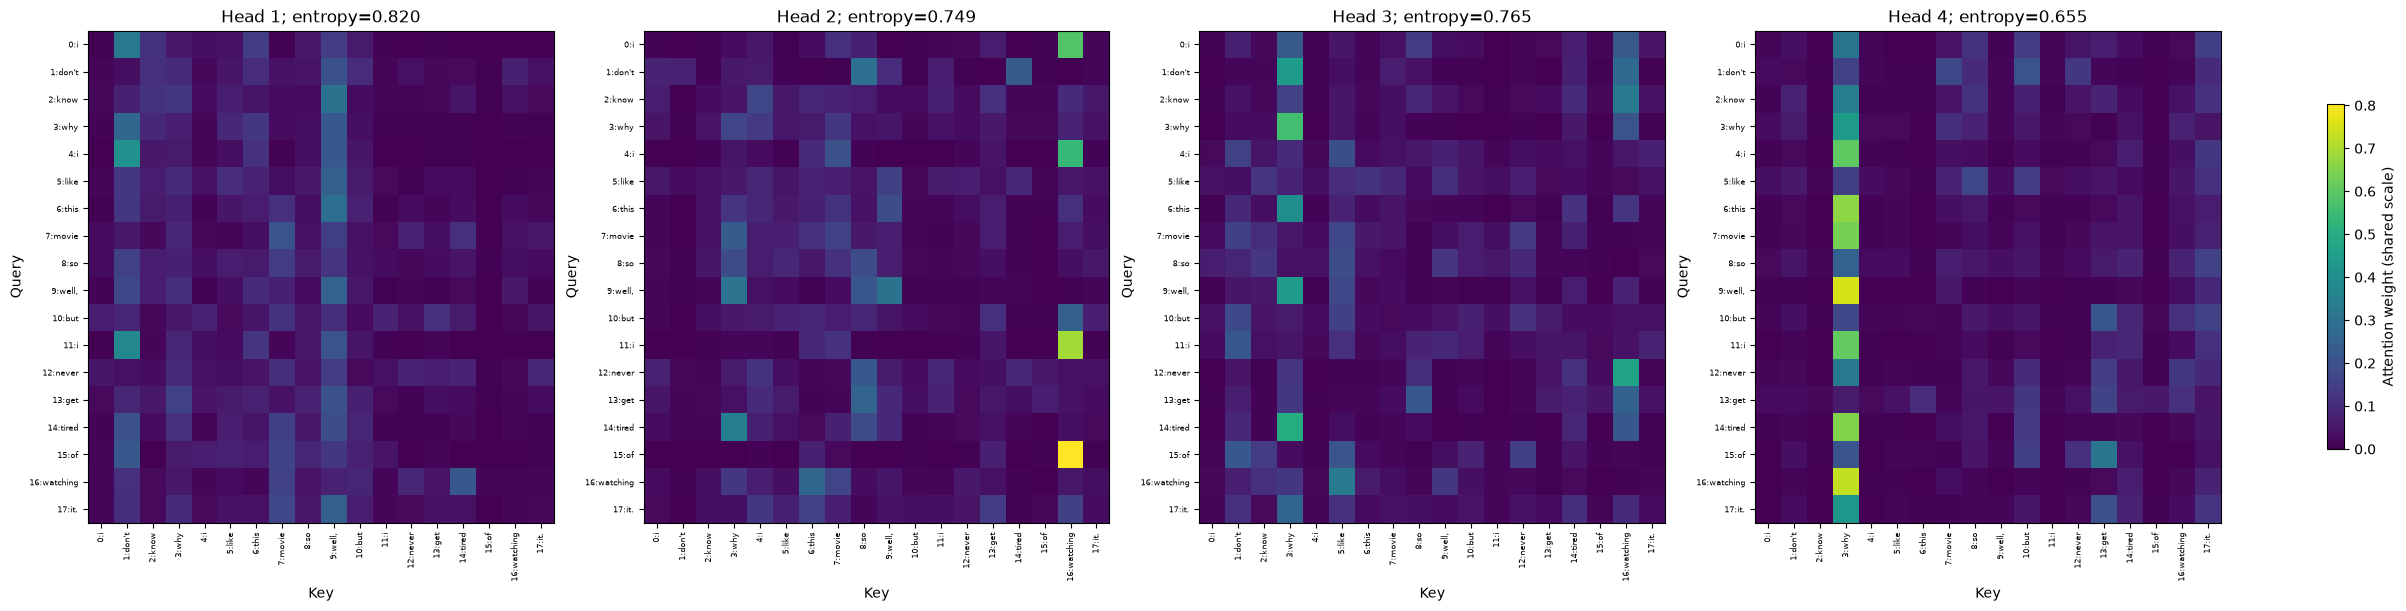

,Head,Normalized mean entropy
0,1,0.819564
1,2,0.748522
2,3,0.765264
3,4,0.655494


,H1,H2,H3,H4
H1,1.000000,0.340766,0.461852,0.333879
H2,0.340766,1.000000,0.413409,0.373170
H3,0.461852,0.413409,1.000000,0.589717
H4,0.333879,0.373170,0.589717,1.000000


**Mẫu 1:** head 4 tập trung nhất theo entropy, head 1 phân tán nhất. Cặp gần nhất H3–H4 có cosine 0.5897; cặp khác nhất H1–H4 có cosine 0.3339. Không cặp nào đạt ngưỡng gần nhau 0.95. Heatmap và chênh lệch entropy/cosine mô tả sự khác nhau về phân bố; không tự gán syntax/semantics hoặc kết luận redundant trên toàn dataset.

Ví dụ 2: validation index=116, ID train chính thức=1180, tokens=35


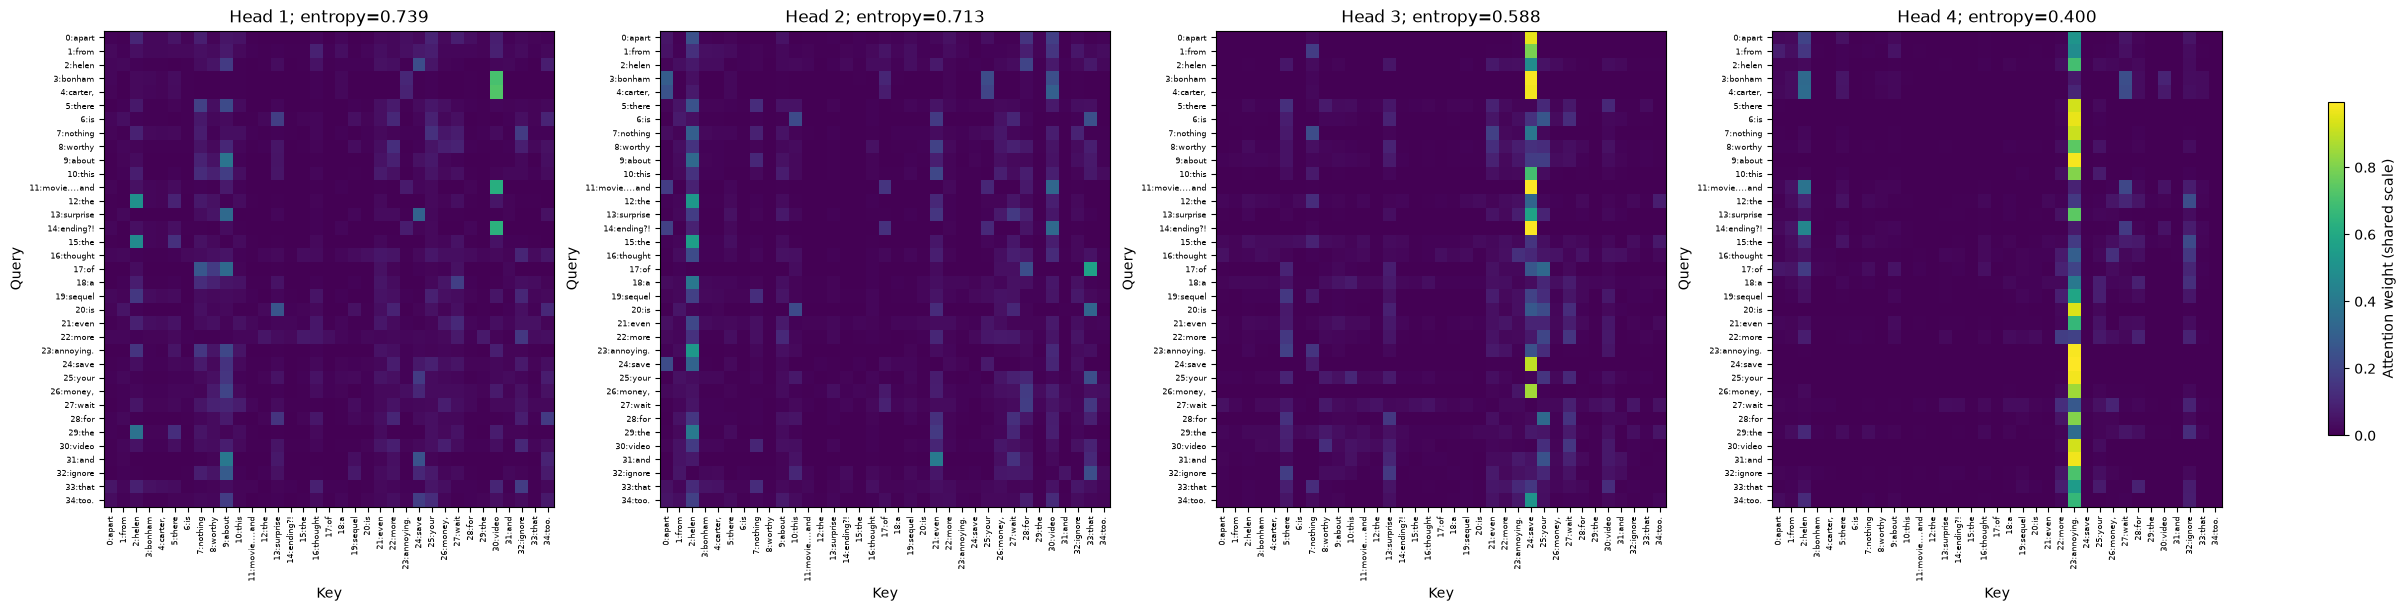

,Head,Normalized mean entropy
0,1,0.738691
1,2,0.713126
2,3,0.588164
3,4,0.399544


,H1,H2,H3,H4
H1,1.000000,0.509541,0.210178,0.103182
H2,0.509541,1.000000,0.106072,0.097372
H3,0.210178,0.106072,1.000000,0.075247
H4,0.103182,0.097372,0.075247,1.000000


**Mẫu 2:** head 4 tập trung nhất theo entropy, head 1 phân tán nhất. Cặp gần nhất H1–H2 có cosine 0.5095; cặp khác nhất H3–H4 có cosine 0.0752. Không cặp nào đạt ngưỡng gần nhau 0.95. Heatmap và chênh lệch entropy/cosine mô tả sự khác nhau về phân bố; không tự gán syntax/semantics hoặc kết luận redundant trên toàn dataset.

Ví dụ 3: validation index=154, ID train chính thức=21678, tokens=38


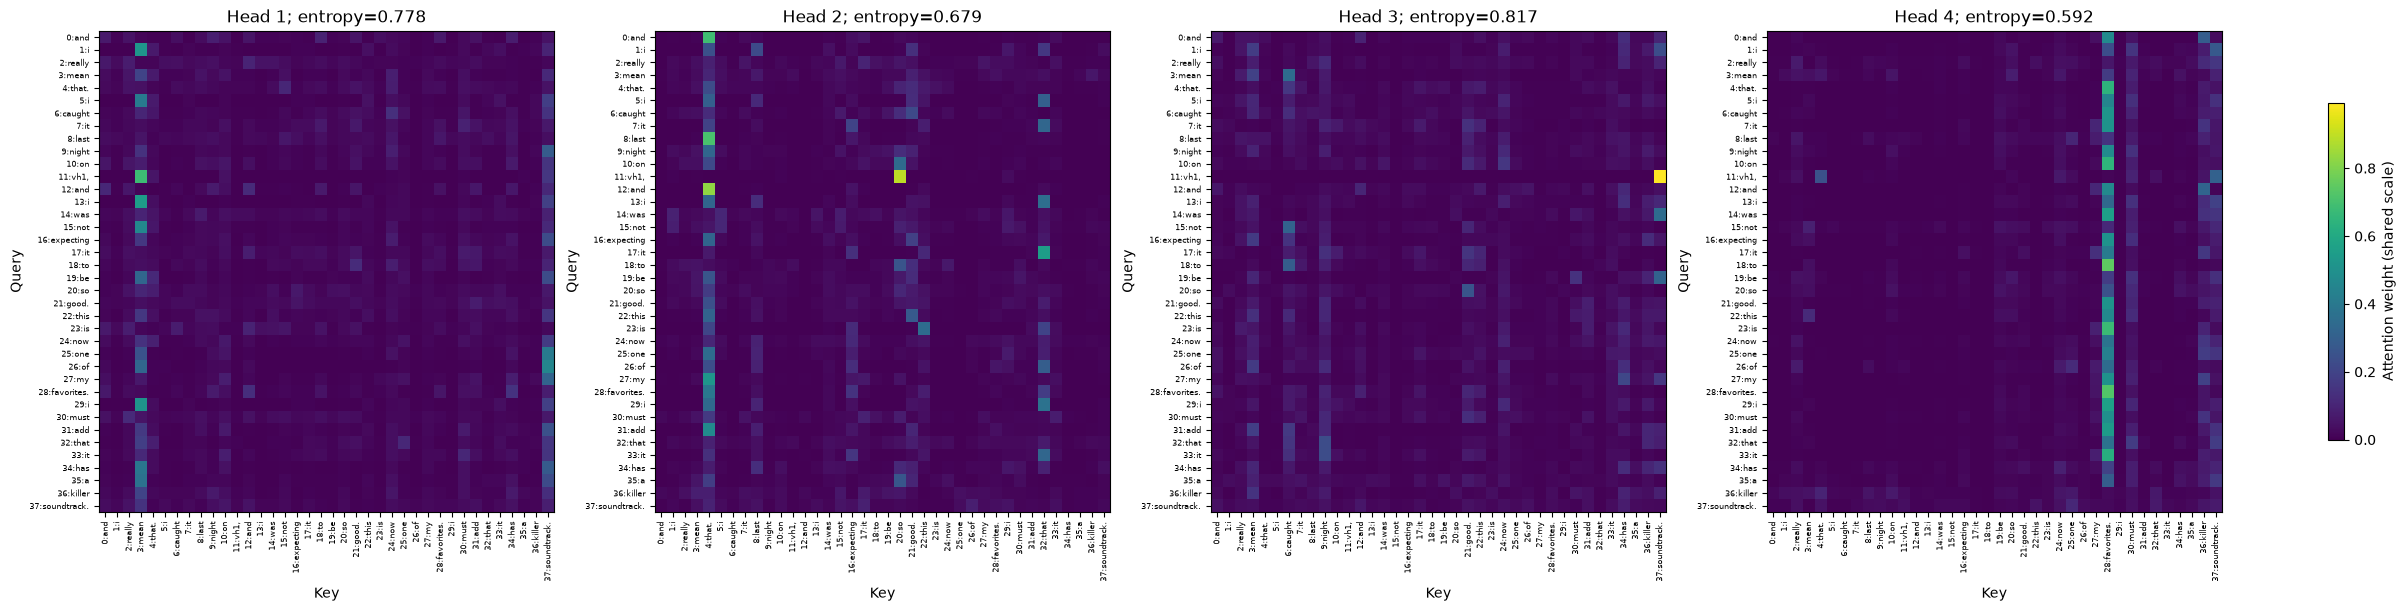

,Head,Normalized mean entropy
0,1,0.778158
1,2,0.679242
2,3,0.816501
3,4,0.592080


,H1,H2,H3,H4
H1,1.000000,0.159052,0.451471,0.215806
H2,0.159052,1.000000,0.151669,0.076085
H3,0.451471,0.151669,1.000000,0.226270
H4,0.215806,0.076085,0.226270,1.000000


**Mẫu 3:** head 4 tập trung nhất theo entropy, head 3 phân tán nhất. Cặp gần nhất H1–H3 có cosine 0.4515; cặp khác nhất H2–H4 có cosine 0.0761. Không cặp nào đạt ngưỡng gần nhau 0.95. Heatmap và chênh lệch entropy/cosine mô tả sự khác nhau về phân bố; không tự gán syntax/semantics hoặc kết luận redundant trên toàn dataset.

In [5]:
ex_diversity_model = ex_load_model(ex_head_runs[4])
ex_selected = [i for i,row in enumerate(ex_tokens["validation"]) if 5<=len(row)<=40][:3]
assert len(ex_selected)==3,"Không đủ ba mẫu theo quy tắc đã định."
ex_diversity_rows = []
for example_number,i in enumerate(ex_selected,1):
    tokens = ex_tokens["validation"][i]
    ids_list = ex_encoded["validation"][i]
    ids = torch.zeros(1,128,dtype=torch.long,device=EX_DEVICE)
    ids[0,:len(ids_list)] = torch.tensor(ids_list,device=EX_DEVICE)
    with torch.no_grad(): _,all_weights = ex_diversity_model(ids,ids.eq(0),return_attention=True)
    n = len(tokens)
    weights = all_weights[0][0,:,:n,:n].cpu()
    assert torch.allclose(weights.sum(-1),torch.ones(4,n),atol=1e-6,rtol=1e-5)
    entropy = -(weights*weights.clamp_min(1e-12).log()).sum(-1).mean(-1)/math.log(n)
    flat = nn.functional.normalize(weights.flatten(1),dim=1)
    similarity = flat@flat.T
    source_id = ex_indices["validation"][i]
    print(f"Ví dụ {example_number}: validation index={i}, ID train chính thức={source_id}, tokens={n}")
    labels = [f"{j}:{t}" for j,t in enumerate(tokens)]
    fig,axes = plt.subplots(1,4,figsize=(24,6),constrained_layout=True)
    for h,ax in enumerate(axes):
        image = ax.imshow(weights[h],vmin=0,vmax=weights.max().item(),cmap="viridis",aspect="auto")
        ax.set(title=f"Head {h+1}; entropy={entropy[h]:.3f}",xlabel="Key",ylabel="Query",xticks=range(n),yticks=range(n))
        ax.set_xticklabels(labels,rotation=90,fontsize=6); ax.set_yticklabels(labels,fontsize=6)
    fig.colorbar(image,ax=axes,shrink=0.7,label="Attention weight (shared scale)")
    fig.savefig(IMAGES_DIR/f"attention_example_{example_number}.png",dpi=150,bbox_inches="tight")
    plt.show()
    entropy_table = pd.DataFrame({"Head":range(1,5),"Normalized mean entropy":entropy.numpy()})
    similarity_table = pd.DataFrame(similarity.numpy(),index=[f"H{h}" for h in range(1,5)],columns=[f"H{h}" for h in range(1,5)])
    display(entropy_table); display(similarity_table)
    entropy_table.to_csv(EX_DIR/f"entropy_example_{example_number}.csv",index=False)
    similarity_table.to_csv(EX_DIR/f"cosine_example_{example_number}.csv")
    pairs = [(similarity[a,b].item(),a+1,b+1) for a in range(4) for b in range(a+1,4)]
    closest,farthest = max(pairs),min(pairs)
    focus,diffuse = entropy.argmin().item()+1,entropy.argmax().item()+1
    display(Markdown(
        f"**Mẫu {example_number}:** head {focus} tập trung nhất theo entropy, head {diffuse} phân tán nhất. "
        f"Cặp gần nhất H{closest[1]}–H{closest[2]} có cosine {closest[0]:.4f}; "
        f"cặp khác nhất H{farthest[1]}–H{farthest[2]} có cosine {farthest[0]:.4f}. "
        + ("Có cặp đạt 0.95, gợi ý pattern gần nhau trên mẫu này. " if closest[0]>=0.95 else "Không cặp nào đạt ngưỡng gần nhau 0.95. ")
        + "Heatmap và chênh lệch entropy/cosine mô tả sự khác nhau về phân bố; "
          "không tự gán syntax/semantics hoặc kết luận redundant trên toàn dataset."
    ))
    ex_diversity_rows.append({"validation_index":i,"source_id":source_id,"entropy":entropy.tolist(),"cosine":similarity.tolist()})
(EX_DIR/"diversity.json").write_text(json.dumps(ex_diversity_rows,indent=2),encoding="utf-8")
del ex_diversity_model


## 21. Experiment 4 — Transformer vs LSTM

Transformer: đúng kết quả 4 heads ở bài 19, một block, FFN 512, PE và masked mean pooling. LSTM: embedding 128 → LSTM hidden 128, một layer một hướng → dropout 0.1 → classifier, dùng trạng thái cuối packed sequence. Không pretrained embedding. Cùng split/vocab, max_length 128, batch 64, optimizer, LR, epochs, loss và cách chọn checkpoint.

Learning curves train là loss/F1 tổng hợp từ minibatch khi đang huấn luyện (dropout bật và trọng số đang cập nhật); validation tính cuối epoch, dropout tắt. Hai đường không đo ở cùng trạng thái model. Báo số tham số thực tế, không ép dung lượng hai model bằng nhau.

**Đối chiếu checkpoint và learning curves:** Transformer được chọn ở epoch 3, LSTM ở epoch 1 theo validation macro F1, dù validation loss của LSTM tiếp tục giảm. Test F1 lần lượt 0.8107 và 0.6478. Transformer nhiều hơn 66.176 tham số; chưa thể tách ảnh hưởng architecture, dung lượng và khả năng tối ưu từ phép so sánh này.

Bắt đầu LSTM, heads=4, length=128, parameters=1412354


  epoch=1: train_loss=0.6773, val_loss=0.6409, val_F1=0.6548


  epoch=2: train_loss=0.6232, val_loss=0.6278, val_F1=0.6479


  epoch=3: train_loss=0.6203, val_loss=0.6156, val_F1=0.6496


Hoàn tất: best epoch=1; test F1=0.6478; time=11.80s


,Model,Parameters,Training time (s),Accuracy,Macro Precision,Macro Recall,Macro F1
0,Transformer (4 heads),1478530,4.193166,0.81088,0.812317,0.81088,0.810662
1,LSTM,1412354,11.796665,0.64820,0.648920,0.64820,0.647774


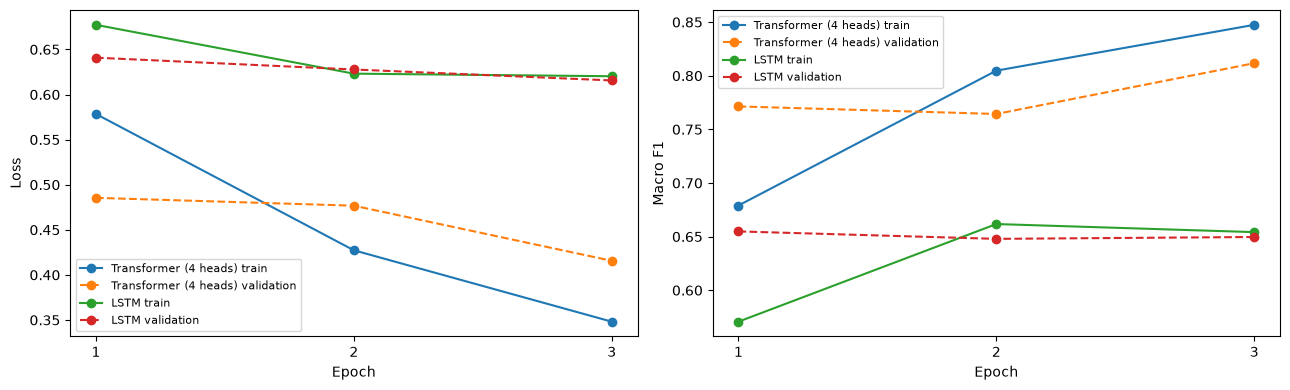

**Kết quả seed này:** Transformer F1=0.8107, LSTM F1=0.6478; chênh lệch Transformer − LSTM là +0.1629. Chênh lệch tham số: +66,176.

**Performance có thể khác do thành phần nào?** LSTM xử lý tuần tự và nén vào trạng thái cuối; self-attention cho token tương tác trực tiếp, PE bổ sung vị trí và masked mean pooling tổng hợp nhiều token. FFN, các cổng LSTM, residual/LayerNorm, dropout và dung lượng model cũng khác nhau. Đó là các khả năng giải thích, chưa phải nguyên nhân đã chứng minh vì chưa có ablation. Không mặc định Transformer thắng; thời gian còn phụ thuộc triển khai, phần cứng và độ dài.

In [6]:
ex_lstm_run = ex_run(model_type="LSTM")
ex_comparison_runs = {"Transformer (4 heads)":ex_head_runs[4],"LSTM":ex_lstm_run}
ex_model_table = pd.DataFrame([
    {"Model":name,"Parameters":r["parameters"],"Training time (s)":r["training_time"],
     "Accuracy":r["test"]["accuracy"],"Macro Precision":r["test"]["precision"],
     "Macro Recall":r["test"]["recall"],"Macro F1":r["test"]["f1"]}
    for name,r in ex_comparison_runs.items()])
display(ex_model_table)
ex_model_table.to_csv(EX_DIR/"transformer_vs_lstm.csv",index=False)
fig,axes = plt.subplots(1,2,figsize=(13,4))
for name,r in ex_comparison_runs.items():
    history = pd.DataFrame(r["history"])
    history.to_csv(EX_DIR/f"history_{r['config']['model'].lower()}.csv",index=False)
    for ax,metric,label in [(axes[0],"loss","Loss"),(axes[1],"f1","Macro F1")]:
        ax.plot(history["epoch"],history[f"train_{metric}"],"o-",label=f"{name} train")
        ax.plot(history["epoch"],history[f"val_{metric}"],"o--",label=f"{name} validation")
        ax.set(xlabel="Epoch",ylabel=label,xticks=[1,2,3]); ax.legend(fontsize=8)
save_lab_figure("transformer_vs_lstm_learning_curves.png")
ex_t,ex_l = ex_head_runs[4],ex_lstm_run
display(Markdown(
    f"**Kết quả seed này:** Transformer F1={ex_t['test']['f1']:.4f}, LSTM F1={ex_l['test']['f1']:.4f}; "
    f"chênh lệch Transformer − LSTM là {ex_t['test']['f1']-ex_l['test']['f1']:+.4f}. "
    f"Chênh lệch tham số: {ex_t['parameters']-ex_l['parameters']:+,}.\n\n"
    "**Performance có thể khác do thành phần nào?** LSTM xử lý tuần tự và nén vào trạng thái cuối; "
    "self-attention cho token tương tác trực tiếp, PE bổ sung vị trí và masked mean pooling tổng hợp nhiều token. "
    "FFN, các cổng LSTM, residual/LayerNorm, dropout và dung lượng model cũng khác nhau. "
    "Đó là các khả năng giải thích, chưa phải nguyên nhân đã chứng minh vì chưa có ablation. "
    "Không mặc định Transformer thắng; thời gian còn phụ thuộc triển khai, phần cứng và độ dài."
))


## 22. Experiment 5 — Sequence length

Transformer d_model=128, heads=4; thử max_length=32,64,128,256, giữ cấu hình khác. Mỗi độ dài có một lượt train độc lập từ model mới; length 128 dùng lại bài 19 vì trùng toàn bộ điều kiện.

Tokens retained (%) đo trên cùng **train 20.000 mẫu**: tổng `min(số token trước truncation, max_length)` / tổng token trước truncation ×100%. Không tính PAD.

Attention memory lý thuyết: **một tensor scores trong một layer**, `B × H × T² × bytes_per_element`, B=64, H=4, float32=4 bytes. Không phải toàn bộ bộ nhớ huấn luyện hoặc model. Fixed padding bảo đảm T thực tế đúng bằng max_length; batch cuối có B nhỏ hơn nhưng bảng luôn dùng B=64. Không đo GPU peak memory. Nếu OOM, ghi lỗi và dừng, không âm thầm giảm batch size.

**Đối chiếu kết quả:** ở length 128→256, token train giữ lại tăng 51.12%→76.51%, F1 tăng 0.8107→0.8349; bộ nhớ một tensor scores tăng 16→64 MiB. Thời gian tăng khoảng 2.91 lần trong lần chạy này. Cả bốn length chạy thành công, không OOM và không thay batch size.

Bắt đầu Transformer, heads=4, length=32, parameters=1478530


  epoch=1: train_loss=0.6410, val_loss=0.5998, val_F1=0.6664


  epoch=2: train_loss=0.5623, val_loss=0.5694, val_F1=0.7002


  epoch=3: train_loss=0.5002, val_loss=0.5814, val_F1=0.7090


Hoàn tất: best epoch=3; test F1=0.6935; time=3.63s


Bắt đầu Transformer, heads=4, length=64, parameters=1478530


... (7 outputs left out)

  epoch=2: train_loss=0.3788, val_loss=0.4007, val_F1=0.8207


  epoch=3: train_loss=0.2954, val_loss=0.3744, val_F1=0.8398


Hoàn tất: best epoch=3; test F1=0.8349; time=12.22s


,Length,Tokens retained (%),Attention memory (MiB),Training time (s),Macro F1
0,32,13.712090,1.0,3.634414,0.693516
1,64,27.124032,4.0,3.452521,0.750449
2,128,51.116288,16.0,4.193166,0.810662
3,256,76.511185,64.0,12.215745,0.834886


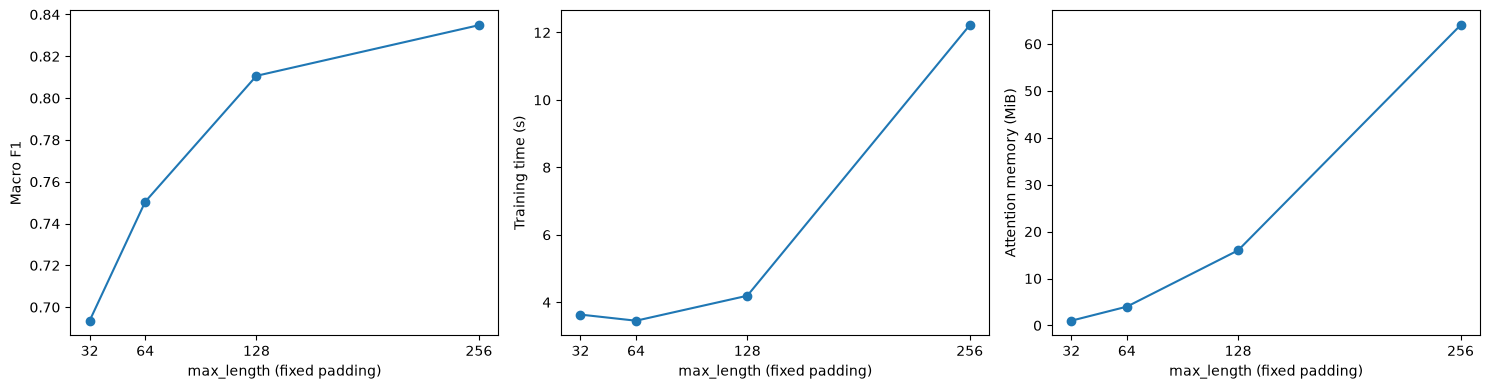

**Chi phí T²:** một attention matrix tăng từ 128²=16.384 lên 256²=65.536 phần tử, gấp 4. Tổng training time hoặc tổng bộ nhớ không nhất thiết tăng đúng 4 lần vì còn embedding, FFN, gradient, optimizer, validation, truyền dữ liệu và mức sử dụng GPU.

**Số liệu thực tế:** từ 128 lên 256, token giữ lại trên train tăng từ 51.12% lên 76.51%; test F1 đổi từ 0.8107 sang 0.8349; tỷ số thời gian là 2.91. Test F1 cao nhất trong bảng tại length 256; đây chỉ là mô tả, không dùng test để chọn checkpoint hay cấu hình chạy tiếp.

**Tại sao không đơn giản tăng sequence length?** Chi phí attention theo T² đòi thêm bộ nhớ/tính toán và có thể OOM; thêm token không bảo đảm thêm tín hiệu hữu ích hoặc F1 cao hơn. Cần cân nhắc tỷ lệ token giữ lại, F1 thực tế và chi phí ở bảng; không suy rộng một seed/một GPU cho mọi bài toán.

In [7]:
ex_length_runs = {length:ex_run(heads=4,max_length=length) for length in [32,64,128,256]}
ex_train_token_total = sum(map(len,ex_tokens["train"]))
ex_bytes = torch.empty((),dtype=torch.float32).element_size()
ex_length_table = pd.DataFrame([
    {"Length":length,"Tokens retained (%)":100*sum(min(len(row),length) for row in ex_tokens["train"])/ex_train_token_total,
     "Attention memory (MiB)":64*4*length**2*ex_bytes/2**20,"Attention scores bytes":64*4*length**2*ex_bytes,
     "Training time (s)":r["training_time"],"Macro F1":r["test"]["f1"],"Accuracy":r["test"]["accuracy"],
     "Macro Precision":r["test"]["precision"],"Macro Recall":r["test"]["recall"]}
    for length,r in ex_length_runs.items()])
display(ex_length_table[["Length","Tokens retained (%)","Attention memory (MiB)","Training time (s)","Macro F1"]])
ex_length_table.to_csv(EX_DIR/"length_results.csv",index=False)
fig,axes = plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,["Macro F1","Training time (s)","Attention memory (MiB)"]):
    ax.plot(ex_length_table["Length"],ex_length_table[col],"o-")
    ax.set(xlabel="max_length (fixed padding)",ylabel=col,xticks=[32,64,128,256])
save_lab_figure("length_f1_time_memory.png")
ex_len128 = ex_length_table.set_index("Length").loc[128]
ex_len256 = ex_length_table.set_index("Length").loc[256]
ex_best_length = int(ex_length_table.loc[ex_length_table["Macro F1"].idxmax(),"Length"])
display(Markdown(
    "**Chi phí T²:** một attention matrix tăng từ 128²=16.384 lên 256²=65.536 phần tử, gấp 4. "
    "Tổng training time hoặc tổng bộ nhớ không nhất thiết tăng đúng 4 lần vì còn embedding, FFN, "
    "gradient, optimizer, validation, truyền dữ liệu và mức sử dụng GPU.\n\n"
    f"**Số liệu thực tế:** từ 128 lên 256, token giữ lại trên train tăng từ {ex_len128['Tokens retained (%)']:.2f}% "
    f"lên {ex_len256['Tokens retained (%)']:.2f}%; test F1 đổi từ {ex_len128['Macro F1']:.4f} "
    f"sang {ex_len256['Macro F1']:.4f}; tỷ số thời gian là "
    f"{ex_len256['Training time (s)']/ex_len128['Training time (s)']:.2f}. "
    f"Test F1 cao nhất trong bảng tại length {ex_best_length}; đây chỉ là mô tả, không dùng test "
    "để chọn checkpoint hay cấu hình chạy tiếp.\n\n"
    "**Tại sao không đơn giản tăng sequence length?** Chi phí attention theo T² đòi thêm bộ nhớ/tính toán "
    "và có thể OOM; thêm token không bảo đảm thêm tín hiệu hữu ích hoặc F1 cao hơn. Cần cân nhắc "
    "tỷ lệ token giữ lại, F1 thực tế và chi phí ở bảng; không suy rộng một seed/một GPU cho mọi bài toán."
))


## 23. Application — Transformer text classification

Em tái sử dụng **cấu hình chuẩn Transformer 4 heads, max_length=128 ở bài 19**, không chọn cấu hình dựa trên test hoặc các câu demo. Checkpoint của cấu hình này đã được chọn bằng validation macro F1, rồi validation loss nếu hòa. Không huấn luyện lại và không báo cáo model khởi tạo ngẫu nhiên như classifier đã học.

Dataset là **IMDb** như LAB 05: nhãn `0=Negative`, `1=Positive`. Dùng lại split và vocabulary từ `artifacts/experiments_19_22/data_protocol.json`: 20.000 train, 5.000 validation và 25.000 test chính thức; vocabulary chỉ xây từ train. Phần này tái sử dụng class `ExTransformerClassifier` ở cell **Mô hình và xử lý padding** phía trên; cần chạy cell định nghĩa đó trước khi chạy ứng dụng. Không cần chạy lại các lượt huấn luyện.

**Pipeline:** Raw text → `lower().split()` → Token IDs (ngoài vocabulary → UNK=1) → Embedding → Sinusoidal PE → encoder dùng `TransformerBlock` tự triển khai → masked mean pooling → Linear 2 logits → softmax → nhãn và xác suất. PAD=0 bị loại ở cả attention key và pooling.

**Tiền xử lý giữ đúng lúc train:** không tự tách dấu câu hoặc đổi tokenizer; giữ **128 token đầu** (right truncation), rồi right padding đến 128. Input rỗng/chỉ khoảng trắng báo lỗi rõ ràng, không gửi chuỗi toàn PAD vào model. Nếu quá max_length, hàm thông báo số token bị bỏ và trả thông tin truncation.

Xác suất softmax là đầu ra model, **chưa mặc nhiên là độ tin cậy đã hiệu chuẩn**. Các câu dưới đây là ví dụ minh họa, không phải bộ test để tính accuracy hay chọn checkpoint.

In [2]:
import hashlib
import json
from pathlib import Path
import torch
import pandas as pd
from IPython.display import display, Markdown

if "ExTransformerClassifier" not in globals():
    raise RuntimeError("Hãy chạy cell định nghĩa mô hình trong phần Mô hình và xử lý padding trước bài 23.")

app_dir = Path("artifacts/experiments_19_22")
app_protocol = json.loads((app_dir / "data_protocol.json").read_text(encoding="utf-8"))
app_data_hash = hashlib.sha256(json.dumps(app_protocol, sort_keys=True).encode()).hexdigest()
assert app_protocol["dataset"] == "stanfordnlp/imdb"
assert app_protocol["tokenizer"] == "lower().split()"
assert {k: len(v) for k,v in app_protocol["indices"].items()} == {"train":20000,"validation":5000,"test":25000}
app_vocab = app_protocol["vocabulary"]
assert app_vocab["<PAD>"] == 0 and app_vocab["<UNK>"] == 1
# Class cũ lấy kích thước embedding từ ex_vocab; bảo đảm đúng vocabulary đã train.
if "ex_vocab" in globals() and ex_vocab != app_vocab:
    raise ValueError("Vocabulary trong phiên không khớp vocabulary của checkpoint.")
ex_vocab = app_vocab
app_core_hash = hashlib.sha256(Path("transformer_block.py").read_bytes()).hexdigest()
app_nb = json.loads(Path("transformer_classification.ipynb").read_text(encoding="utf-8"))
app_sources = ["".join(c["source"]) if isinstance(c["source"],list) else c["source"]
               for c in app_nb["cells"] if c["cell_type"] == "code"]
app_model_hash = hashlib.sha256("\n".join(s for s in app_sources if
    s.startswith("class ExSinusoidalPE") or s.startswith("def ex_make_loaders")).encode()).hexdigest()
app_matching = []
for path in sorted(app_dir.glob("transformer_h4_t128_*.pt")):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    cfg = checkpoint["config"]
    required = {"model":"Transformer","heads":4,"max_length":128,"d_model":128,
                "blocks":1,"d_ff":512,"dropout":0.1,"pooling":"masked_mean",
                "position":"sinusoidal","loss":"CrossEntropyLoss","padding":"fixed",
                "data_hash":app_data_hash,"core_hash":app_core_hash,"model_hash":app_model_hash}
    if all(cfg.get(k) == v for k,v in required.items()):
        app_matching.append((path,checkpoint))
if len(app_matching) != 1:
    raise RuntimeError(f"Cần đúng một checkpoint chuẩn phù hợp; tìm được {len(app_matching)}. Không dùng model ngẫu nhiên.")
app_checkpoint_path, app_checkpoint = app_matching[0]
app_config = app_checkpoint["config"]
app_result = app_checkpoint["result"]
assert app_result["config"] == app_config
# Đối chiếu epoch tốt nhất theo validation, không dùng test để chọn.
app_best = max(app_result["history"], key=lambda r:(r["val_f1"],-r["val_loss"],-r["epoch"]))
assert app_result["best_epoch"] == app_best["epoch"]
app_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
app_model = ExTransformerClassifier(app_config["heads"])
app_model.load_state_dict(app_checkpoint["state_dict"], strict=True)
app_model = app_model.to(app_device).eval()
app_max_length = app_config["max_length"]
app_labels = {0:"Negative",1:"Positive"}
assert sum(p.numel() for p in app_model.parameters() if p.requires_grad) == app_result["parameters"]
print("Checkpoint đã tải:", app_checkpoint_path)
print("Thiết bị:",app_device,"; max_length:",app_max_length,"; nhãn:",app_labels)
print("Epoch được validation chọn:",app_result["best_epoch"],"; validation macro F1:",app_result["best_val_f1"])
print("Không huấn luyện lại; các metric test dưới đây là kết quả định lượng đã lưu từ bài 19.")
display(pd.DataFrame([{"Dataset":"IMDb official test", "Samples":25000,
    "Accuracy":app_result["test"]["accuracy"],"Macro Precision":app_result["test"]["precision"],
    "Macro Recall":app_result["test"]["recall"],"Macro F1":app_result["test"]["f1"]}]))


Checkpoint đã tải: artifacts\experiments_19_22\transformer_h4_t128_fac251c06717.pt
Thiết bị: cuda ; max_length: 128 ; nhãn: {0: 'Negative', 1: 'Positive'}
Epoch được validation chọn: 3 ; validation macro F1: 0.8116627021098382
Không huấn luyện lại; các metric test dưới đây là kết quả định lượng đã lưu từ bài 19.


,Dataset,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1
0,IMDb official test,25000,0.81088,0.812317,0.81088,0.810662


### Hàm dự đoán và kiểm tra input

`predict_sentiment(text)` trả dictionary gồm văn bản gốc, nhãn dự đoán, xác suất nhãn đó, xác suất từng nhãn và thông tin truncation/UNK. Hàm kiểm tra kiểu input, từ chối chuỗi rỗng bằng `ValueError`, đặt `eval()` và chạy forward dưới `torch.no_grad()`. Model có hai logits và train bằng CrossEntropyLoss nên dùng softmax trên chiều nhãn.

Cell này kiểm tra thêm input rỗng, chỉ khoảng trắng và token UNK. Các kiểm tra kỹ thuật này không phải đánh giá chất lượng sentiment.

In [3]:
def predict_sentiment(text):
    """Dự đoán bằng đúng tokenizer/vocab/checkpoint IMDb đã huấn luyện."""
    if not isinstance(text,str):
        raise TypeError("Input phải là một chuỗi văn bản.")
    tokens = text.lower().split()
    if not tokens:
        raise ValueError("Input rỗng hoặc chỉ có khoảng trắng; hãy nhập review có nội dung.")
    kept = tokens[:app_max_length]
    token_ids = [app_vocab.get(token,app_vocab["<UNK>"]) for token in kept]
    dropped = len(tokens)-len(kept)
    message = (f"Input có {len(tokens)} token, vượt max_length={app_max_length}: "
               f"giữ {len(kept)} token đầu, bỏ {dropped} token cuối.") if dropped else "Không truncation."
    if dropped:
        print("Thông báo truncation:",message)
    ids = torch.full((1,app_max_length),app_vocab["<PAD>"],dtype=torch.long,device=app_device)
    ids[0,:len(token_ids)] = torch.tensor(token_ids,dtype=torch.long,device=app_device)
    padding_mask = ids.eq(app_vocab["<PAD>"])
    app_model.eval()
    with torch.no_grad():
        logits = app_model(ids,padding_mask)
        if logits.shape != (1,2) or not torch.isfinite(logits).all():
            raise RuntimeError("Logits không hợp lệ cho classifier hai nhãn.")
        probabilities = torch.softmax(logits,dim=-1)[0].cpu()
    predicted_id = int(probabilities.argmax())
    return {"text":text,"prediction":app_labels[predicted_id],"predicted_id":predicted_id,
            "probability":float(probabilities[predicted_id]),
            "probabilities":{app_labels[i]:float(probabilities[i]) for i in range(2)},
            "truncation":{"truncated":bool(dropped),"original_tokens":len(tokens),
                          "retained_tokens":len(kept),"dropped_tokens":dropped,
                          "max_length":app_max_length,"strategy":"keep first tokens; right truncation",
                          "message":message},
            "unknown_tokens_retained":sum(token not in app_vocab for token in kept)}


def show_sentiment(result):
    """Hiển thị kết quả thật, không áp đặt nhãn mong đợi cho ví dụ."""
    print("Input:",repr(result["text"]))
    print("Prediction:",result["prediction"])
    print(f"Probability: {result['probability']:.6f}")
    print(f"P(Positive)={result['probabilities']['Positive']:.6f}; P(Negative)={result['probabilities']['Negative']:.6f}")
    info = result["truncation"]
    print(f"Tokens: {info['original_tokens']}; retained: {info['retained_tokens']}; "
          f"truncated: {info['truncated']}; UNK retained: {result['unknown_tokens_retained']}")
    print(info["message"])

for empty_input in ["","   ","\n\t"]:
    try:
        predict_sentiment(empty_input)
    except ValueError as error:
        print(f"PASS {empty_input!r}:",error)
    else:
        raise AssertionError("Input rỗng phải bị từ chối.")
app_unk_token = "zzzz_unseen_sentiment_token_2026"
assert app_unk_token not in app_vocab
app_unk_result = predict_sentiment(app_unk_token)
assert app_unk_result["unknown_tokens_retained"] == 1
assert abs(sum(app_unk_result["probabilities"].values())-1.0) < 1e-6
print("PASS: token ngoài vocabulary được ánh xạ UNK và xác suất hợp lệ.")


PASS '': Input rỗng hoặc chỉ có khoảng trắng; hãy nhập review có nội dung.
PASS '   ': Input rỗng hoặc chỉ có khoảng trắng; hãy nhập review có nội dung.
PASS '\n\t': Input rỗng hoặc chỉ có khoảng trắng; hãy nhập review có nội dung.


PASS: token ngoài vocabulary được ánh xạ UNK và xác suất hợp lệ.


### Các nhóm ví dụ bắt buộc và bảng dự đoán

Các ví dụ được định trước khi xem kết quả. Đoạn dài có nhiều câu và dài hơn 128 token để quan sát truncation; nội dung cuối đoạn có thể bị bỏ. Hiển thị nguyên văn, số token và trạng thái truncation, không sửa câu để ép model trả nhãn mong đợi. Không gán nhãn đúng tuyệt đối cho câu mơ hồ hoặc chứa cảm xúc đối lập.

In [4]:
app_long_review = (
    "I watched this movie on a quiet evening after several friends recommended it to me. "
    "The opening scenes were beautifully photographed, and the music created an inviting atmosphere. "
    "At first I enjoyed following the main character through a city filled with interesting people. "
    "Several conversations felt natural, and the supporting actors brought warmth to otherwise ordinary moments. "
    "However, the middle section repeated the same conflicts without giving the characters convincing reasons to change. "
    "A mysterious letter appeared, disappeared, and returned whenever the story needed another surprise. "
    "Some jokes were funny, but others interrupted emotional scenes that deserved more patience. "
    "I kept hoping the final act would connect these separate ideas into something meaningful. "
    "The ending finally gave the characters a chance to speak honestly about their mistakes and their hopes. "
    "Although the journey was uneven and sometimes frustrating, those final conversations were moving. "
    "I left the film feeling glad that I had watched it, and I would recommend it to viewers who appreciate imperfect but sincere stories."
)
app_examples = [
    ("Short","I loved this movie."),
    ("Short","This movie was awful."),
    ("Long",app_long_review),
    ("Negation","The movie was good."),
    ("Negation","The movie was not good."),
    ("Contrast","The acting was excellent, but the story was terrible."),
    ("Contrast","The story was slow, but I really enjoyed the movie overall."),
    ("Ambiguous sentiment","The movie was okay, neither impressive nor disappointing."),
    ("Additional example","I really enjoyed this movie."),
]
app_predictions = []
for category,text in app_examples:
    print("\n===",category,"===")
    result = predict_sentiment(text)
    app_predictions.append({"category":category,**result})
    show_sentiment(result)
    assert abs(sum(result["probabilities"].values())-1.0) < 1e-6
    assert result["probability"] == result["probabilities"][result["prediction"]]
app_table = pd.DataFrame([
    {"Category":r["category"],"Text":r["text"],"Prediction":r["prediction"],
     "P(Positive)":r["probabilities"]["Positive"],"P(Negative)":r["probabilities"]["Negative"],
     "Truncated":r["truncation"]["truncated"]} for r in app_predictions])
# Không cắt ngắn text trong bảng; chỉ định dạng số lúc hiển thị.
with pd.option_context("display.max_colwidth",None,"display.max_rows",None):
    display(app_table.style.format({"P(Positive)":"{:.6f}","P(Negative)":"{:.6f}"})
            .set_properties(subset=["Text"],**{"white-space":"normal","max-width":"650px"}))
app_long_result = next(r for r in app_predictions if r["category"]=="Long")
assert app_long_result["truncation"]["truncated"]
print("\nPhần cuối bị bỏ khỏi review dài:")
print(" ".join(app_long_review.lower().split()[app_max_length:]))



=== Short ===
Input: 'I loved this movie.'
Prediction: Negative
Probability: 0.786263
P(Positive)=0.213737; P(Negative)=0.786263
Tokens: 4; retained: 4; truncated: False; UNK retained: 0
Không truncation.

=== Short ===
Input: 'This movie was awful.'
Prediction: Negative
Probability: 0.999488
P(Positive)=0.000512; P(Negative)=0.999488
Tokens: 4; retained: 4; truncated: False; UNK retained: 0
Không truncation.

=== Long ===
Thông báo truncation: Input có 167 token, vượt max_length=128: giữ 128 token đầu, bỏ 39 token cuối.
Input: 'I watched this movie on a quiet evening after several friends recommended it to me. The opening scenes were beautifully photographed, and the music created an inviting atmosphere. At first I enjoyed following the main character through a city filled with interesting people. Several conversations felt natural, and the supporting actors brought warmth to otherwise ordinary moments. However, the middle section repeated the same conflicts without giving the charac

,Category,Text,Prediction,P(Positive),P(Negative),Truncated
0,Short,I loved this movie.,Negative,0.213737,0.786263,False
1,Short,This movie was awful.,Negative,0.000512,0.999488,False
2,Long,"I watched this movie on a quiet evening after several friends recommended it to me. The opening scenes were beautifully photographed, and the music created an inviting atmosphere. At first I enjoyed following the main character through a city filled with interesting people. Several conversations felt natural, and the supporting actors brought warmth to otherwise ordinary moments. However, the middle section repeated the same conflicts without giving the characters convincing reasons to change. A mysterious letter appeared, disappeared, and returned whenever the story needed another surprise. Some jokes were funny, but others interrupted emotional scenes that deserved more patience. I kept hoping the final act would connect these separate ideas into something meaningful. The ending finally gave the characters a chance to speak honestly about their mistakes and their hopes. Although the journey was uneven and sometimes frustrating, those final conversations were moving. I left the film feeling glad that I had watched it, and I would recommend it to viewers who appreciate imperfect but sincere stories.",Positive,0.727286,0.272714,True
3,Negation,The movie was good.,Negative,0.013958,0.986042,False
4,Negation,The movie was not good.,Negative,0.005287,0.994713,False
5,Contrast,"The acting was excellent, but the story was terrible.",Negative,0.006518,0.993482,False
6,Contrast,"The story was slow, but I really enjoyed the movie overall.",Negative,0.308625,0.691375,False
7,Ambiguous sentiment,"The movie was okay, neither impressive nor disappointing.",Negative,0.001471,0.998529,False
8,Additional example,I really enjoyed this movie.,Positive,0.977862,0.022138,False



Phần cuối bị bỏ khỏi review dài:
their hopes. although the journey was uneven and sometimes frustrating, those final conversations were moving. i left the film feeling glad that i had watched it, and i would recommend it to viewers who appreciate imperfect but sincere stories.


### Nhận xét từ kết quả thực tế

Cell dưới lấy trực tiếp các xác suất vừa tính để nhận xét về negation, contrast, câu mơ hồ và truncation. Không dùng các ví dụ minh họa để ước lượng chất lượng trên toàn bộ IMDb, không coi xác suất lớn là bằng chứng model đã hiểu nghĩa hoặc đã được hiệu chuẩn.

In [5]:
app_neg = [r for r in app_predictions if r["category"]=="Negation"]
app_delta = app_neg[1]["probabilities"]["Positive"]-app_neg[0]["probabilities"]["Positive"]
app_label_change = app_neg[0]["prediction"] != app_neg[1]["prediction"]
app_contrast = [r for r in app_predictions if r["category"]=="Contrast"]
app_ambiguous = next(r for r in app_predictions if r["category"]=="Ambiguous sentiment")
app_info = app_long_result["truncation"]
app_notes = [
    f"**Negation:** P(Positive) của ‘good’ = {app_neg[0]['probabilities']['Positive']:.6f}; "
    f"‘not good’ = {app_neg[1]['probabilities']['Positive']:.6f}, chênh lệch {app_delta:+.6f}. "
    + ("Xác suất Positive giảm khi thêm ‘not’. " if app_delta<0 else "Xác suất Positive không giảm khi thêm ‘not’; cặp này bộc lộ hạn chế xử lý phủ định. ")
    + ("Nhãn có đổi. " if app_label_change else "Nhãn không đổi. ")
    + "Một cặp câu chưa đủ kết luận model hiểu phủ định nói chung.",
    "**Contrast:** câu acting excellent / story terrible được dự đoán "
    f"{app_contrast[0]['prediction']}, P(Positive)={app_contrast[0]['probabilities']['Positive']:.6f}; "
    "câu story slow / enjoyed overall được dự đoán "
    f"{app_contrast[1]['prediction']}, P(Positive)={app_contrast[1]['probabilities']['Positive']:.6f}. "
    "Đây là phản ứng thực tế với hai câu cảm xúc đối lập; không có nhãn đúng tuyệt đối áp đặt ở đây, "
    "và chưa chứng minh model luôn ưu tiên đúng vế sau ‘but’.",
    f"**Cảm xúc mơ hồ:** model dự đoán {app_ambiguous['prediction']} với xác suất nhãn đó "
    f"{app_ambiguous['probability']:.6f}. "
    + ("Phân bố nghiêng mạnh về một nhãn (>0.9), có dấu hiệu tự tin cao đối với ví dụ mơ hồ này. "
       if app_ambiguous['probability']>0.9 else
       "Xác suất nhãn cao nhất không vượt 0.9; số liệu này chưa đủ để khẳng định model quá tự tin hay đã được hiệu chuẩn. ")
    + "Mốc 0.9 chỉ mô tả độ lệch của đầu ra, không phải kiểm định calibration; không gán nhãn đúng tuyệt đối cho câu này.",
    f"**Review dài:** {app_info['original_tokens']} token, giữ {app_info['retained_tokens']}, "
    f"bỏ {app_info['dropped_tokens']}; Truncated={app_info['truncated']}. "
    "Dự đoán chỉ dựa trên phần đầu được giữ lại; các kết luận ở cuối review có thể bị mất nên "
    "không đại diện cho việc model đã đọc toàn đoạn. Chưa đo mức thay đổi nhãn nếu giữ đầy đủ ngữ cảnh.",
    "**Phạm vi:** softmax chuyển hai logits CrossEntropyLoss thành phân bố xác suất của model, "
    "chưa mặc nhiên là độ tin cậy đã hiệu chuẩn. Các câu demo ở đây khác với đánh giá định lượng "
    "trên 25.000 mẫu test đã báo ở bài 19; không dùng chúng để tính accuracy, chọn model hoặc checkpoint."
]
display(Markdown("\n\n".join(app_notes)))


**Negation:** P(Positive) của ‘good’ = 0.013958; ‘not good’ = 0.005287, chênh lệch -0.008672. Xác suất Positive giảm khi thêm ‘not’. Nhãn không đổi. Một cặp câu chưa đủ kết luận model hiểu phủ định nói chung.

**Contrast:** câu acting excellent / story terrible được dự đoán Negative, P(Positive)=0.006518; câu story slow / enjoyed overall được dự đoán Negative, P(Positive)=0.308625. Đây là phản ứng thực tế với hai câu cảm xúc đối lập; không có nhãn đúng tuyệt đối áp đặt ở đây, và chưa chứng minh model luôn ưu tiên đúng vế sau ‘but’.

**Cảm xúc mơ hồ:** model dự đoán Negative với xác suất nhãn đó 0.998529. Phân bố nghiêng mạnh về một nhãn (>0.9), có dấu hiệu tự tin cao đối với ví dụ mơ hồ này. Mốc 0.9 chỉ mô tả độ lệch của đầu ra, không phải kiểm định calibration; không gán nhãn đúng tuyệt đối cho câu này.

**Review dài:** 167 token, giữ 128, bỏ 39; Truncated=True. Dự đoán chỉ dựa trên phần đầu được giữ lại; các kết luận ở cuối review có thể bị mất nên không đại diện cho việc model đã đọc toàn đoạn. Chưa đo mức thay đổi nhãn nếu giữ đầy đủ ngữ cảnh.

**Phạm vi:** softmax chuyển hai logits CrossEntropyLoss thành phân bố xác suất của model, chưa mặc nhiên là độ tin cậy đã hiệu chuẩn. Các câu demo ở đây khác với đánh giá định lượng trên 25.000 mẫu test đã báo ở bài 19; không dùng chúng để tính accuracy, chọn model hoặc checkpoint.

## 25. Experiment 6 — Pooling strategy

Em so sánh **Mean** và **CLS-style** trên IMDb, giữ split/vocabulary/tokenizer đã chuẩn bị ở bài 19–22. Chạy các cell chuẩn bị chung (dữ liệu, định nghĩa mô hình và hàm huấn luyện/đánh giá) trước mục này; không cần chạy lại experiment cũ. Vocabulary gốc chỉ fit trên train, sau đó thêm một token đặc biệt `[CLS]` với ID riêng dùng chung cho hai model; không thay vocabulary/model của các bài trước.

Cả hai nhận input **`[CLS] + tối đa 127 token nội dung + PAD`**, tổng max_length=128, right truncation/right padding. `[CLS]` có embedding học được riêng, không phải PAD và tham gia self-attention ở cả hai cấu hình. Mean chỉ lấy trung bình hidden states cuối của **token nội dung hợp lệ**, loại cả CLS và PAD. CLS-style lấy **hidden state sau encoder** tại vị trí 0, không lấy embedding CLS trước encoder.

Giữ chung embedding dimension=128, 4 heads, FFN=512, một encoder block `TransformerBlock` tự ghép, sinusoidal PE, dropout residual=0.1, Linear(128,2), float32; batch=64, Adam LR=0.001, CrossEntropyLoss và 3 epochs. Nhãn 0=Negative, 1=Positive. Hai model nạp **cùng state_dict ban đầu**, rồi huấn luyện riêng với optimizer mới, seed=42 và thứ tự minibatch giống nhau. Không chuyển cách pooling trên checkpoint Mean đã học.

Checkpoint chọn bằng validation macro F1, hòa thì loss thấp hơn rồi epoch sớm hơn; test chỉ đánh giá sau lựa chọn. Accuracy/macro F1 dùng lại hàm đánh giá cũ (macro metrics có `zero_division=0`).

**Thời gian:** perf_counter, đồng bộ CUDA trước/sau; **bao gồm train và validation mỗi epoch**, sao chép best state về CPU và logging; loại đọc dữ liệu, tạo model/loader/optimizer, warm-up, lưu checkpoint, test và vẽ. Mỗi cấu hình warm-up một bước forward/backward/Adam trên train, sau đó bỏ toàn bộ cập nhật, nạp lại state ban đầu, tạo optimizer mới và reset seed trước khoảng đo. Cùng cách đo cho cả hai; một lượt đo vẫn có nhiễu. Artifacts riêng nằm trong `artifacts/experiment_25/`; chỉ tái sử dụng khi khớp cấu hình và fingerprint.


In [4]:
# Bài 25 dùng lại pipeline và các hàm sẵn có, không thay globals của ứng dụng bài 23.
import copy, hashlib, json
from pathlib import Path
from time import perf_counter
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from transformer_block import TransformerBlock

pool_required = ["ex_encoded","ex_labels","ex_vocab","ex_data_hash","EX_DEVICE",
                 "ExSinusoidalPE","ex_evaluate","ex_metrics","ex_seed","ex_sync"]
pool_missing = [name for name in pool_required if name not in globals()]
if pool_missing:
    raise RuntimeError("Cần chạy các cell chuẩn bị chung của bài 19–22 trước; thiếu: "+", ".join(pool_missing))
POOL_DEVICE = EX_DEVICE
POOL_DIR = Path("artifacts/experiment_25")
POOL_DIR.mkdir(parents=True,exist_ok=True)
pool_vocab = dict(ex_vocab)
assert "[CLS]" not in pool_vocab
POOL_CLS_ID = len(pool_vocab)
pool_vocab["[CLS]"] = POOL_CLS_ID
POOL_PAD_ID = pool_vocab["<PAD>"]
POOL_LENGTH = 128
assert POOL_CLS_ID != POOL_PAD_ID
# Dữ liệu nội dung đã encode bằng vocab train cũ; các ID đó không thay đổi.
pool_datasets = {}
for name,rows in ex_encoded.items():
    ids = torch.full((len(rows),POOL_LENGTH),POOL_PAD_ID,dtype=torch.long)
    ids[:,0] = POOL_CLS_ID
    for i,row in enumerate(rows):
        content = row[:POOL_LENGTH-1]
        if not content: raise ValueError("Mean pooling cần ít nhất một token nội dung.")
        ids[i,1:1+len(content)] = torch.tensor(content,dtype=torch.long)
    pool_datasets[name] = TensorDataset(ids,torch.tensor(ex_labels[name],dtype=torch.long))


def pool_make_loaders():
    return {name:DataLoader(dataset,batch_size=64,shuffle=(name=="train"),num_workers=0,
        generator=torch.Generator().manual_seed(42),pin_memory=(POOL_DEVICE.type=="cuda"))
        for name,dataset in pool_datasets.items()}


class PoolingTransformerClassifier(nn.Module):
    """Hai chế độ chỉ khác phép lấy representation sau encoder."""
    def __init__(self,pooling):
        super().__init__()
        if pooling not in ["Mean","CLS-style"]: raise ValueError("Pooling không hợp lệ")
        self.pooling = pooling
        self.embedding = nn.Embedding(len(pool_vocab),128,padding_idx=POOL_PAD_ID)
        self.position = ExSinusoidalPE()
        self.blocks = nn.ModuleList([TransformerBlock(128,4,512)])
        self.classifier = nn.Linear(128,2)

    def encode(self,ids,padding_mask):
        x = self.position(self.embedding(ids))
        for block in self.blocks: x = block(x,padding_mask=padding_mask)
        return x

    def pool(self,hidden,ids,padding_mask):
        if self.pooling == "CLS-style":
            return hidden[:,0,:]  # Hidden state CLS cuối encoder, không phải embedding ban đầu.
        content_mask = (~padding_mask) & ids.ne(POOL_CLS_ID)
        count = content_mask.sum(1,keepdim=True)
        if (count==0).any(): raise ValueError("Sequence không có token nội dung để mean pooling")
        return (hidden*content_mask.unsqueeze(-1)).sum(1)/count

    def forward(self,ids,padding_mask):
        hidden = self.encode(ids,padding_mask)
        return self.classifier(self.pool(hidden,ids,padding_mask))


def pool_state_hash(state):
    digest = hashlib.sha256()
    for name,tensor in sorted(state.items()):
        digest.update(name.encode()); digest.update(str(tensor.dtype).encode())
        digest.update(str(tuple(tensor.shape)).encode()); digest.update(tensor.cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

ex_seed()
pool_initial_model = PoolingTransformerClassifier("Mean")
pool_initial_state = copy.deepcopy(pool_initial_model.state_dict())
POOL_INITIAL_HASH = pool_state_hash(pool_initial_state)
pool_cls_probe = PoolingTransformerClassifier("CLS-style")
pool_cls_probe.load_state_dict(pool_initial_state)
assert pool_state_hash(pool_cls_probe.state_dict()) == POOL_INITIAL_HASH
pool_parameter_counts = {model.pooling:sum(p.numel() for p in model.parameters() if p.requires_grad)
                         for model in [pool_initial_model,pool_cls_probe]}
assert len(set(pool_parameter_counts.values()))==1
# Kiểm tra trực tiếp Mean bỏ CLS/PAD, CLS-style lấy đúng hidden state vị trí 0.
probe_ids = torch.tensor([[POOL_CLS_ID,2,3,POOL_PAD_ID]])
probe_mask = probe_ids.eq(POOL_PAD_ID)
probe_hidden = torch.randn(1,4,128)
assert torch.allclose(pool_initial_model.pool(probe_hidden,probe_ids,probe_mask),probe_hidden[:,1:3].mean(1))
assert torch.equal(pool_cls_probe.pool(probe_hidden,probe_ids,probe_mask),probe_hidden[:,0])
pool_initial_model.eval()
with torch.no_grad():
    x = pool_initial_model.position(pool_initial_model.embedding(probe_ids))
    h,w = pool_initial_model.blocks[0](x,padding_mask=probe_mask,return_attention=True)
    assert (w[:,:,:,0][:,:,:3] > 0).all(), "CLS phải tham gia attention như key hợp lệ"
    assert (w[:,:,:,-1] == 0).all(), "PAD phải bị loại khỏi key"
    before = pool_initial_model(probe_ids,probe_mask)
    after = pool_initial_model(probe_ids[:,:3],probe_mask[:,:3])
    assert torch.allclose(before,after,atol=1e-6,rtol=1e-5)
print("PASS: cùng state ban đầu; cùng tham số; Mean loại CLS/PAD; CLS-style lấy hidden cuối; CLS tham gia attention.")
print("Thiết bị:",POOL_DEVICE,torch.cuda.get_device_name(0) if POOL_DEVICE.type=="cuda" else "CPU")
print("CLS ID:",POOL_CLS_ID,"; vocabulary size:",len(pool_vocab),"; content limit:",POOL_LENGTH-1)
print("Parameters:",pool_parameter_counts,"; initial SHA256:",POOL_INITIAL_HASH)
del pool_initial_model,pool_cls_probe


PASS: cùng state ban đầu; cùng tham số; Mean loại CLS/PAD; CLS-style lấy hidden cuối; CLS tham gia attention.
Thiết bị: cuda NVIDIA GeForce RTX 5060 Ti
CLS ID: 10000 ; vocabulary size: 10001 ; content limit: 127
Parameters: {'Mean': 1478658, 'CLS-style': 1478658} ; initial SHA256: c8fa9bd3202d37058ac5fbfd6de744807137a089766b3fc68bdfbd696ff08fc1


### Huấn luyện riêng từ cùng khởi tạo và đánh giá

Các checkpoint từ bài 19 không có CLS nên không được tái sử dụng làm kết quả so sánh này. Mỗi lượt train phía dưới xác nhận hash state ban đầu, dùng loader mới và optimizer mới. Dữ liệu/split và encoder tự triển khai vẫn được tái sử dụng. Cache của chính bài 25 chỉ được nạp khi khớp toàn bộ protocol; thời gian trong cache là thời gian huấn luyện gốc.

In [5]:
pool_nb = json.loads(Path("transformer_classification.ipynb").read_text(encoding="utf-8"))
pool_sources = ["".join(c["source"]) if isinstance(c["source"],list) else c["source"]
                for c in pool_nb["cells"] if c["cell_type"]=="code"]
POOL_CODE_HASH = hashlib.sha256("\n".join(s for s in pool_sources if
    "class PoolingTransformerClassifier" in s or s.startswith("pool_nb =")
    or s.startswith("def ex_make_loaders") or s.startswith("class ExSinusoidalPE")).encode()).hexdigest()
POOL_COMMON = {"data_hash":ex_data_hash,"core_hash":hashlib.sha256(Path("transformer_block.py").read_bytes()).hexdigest(),
    "code_hash":POOL_CODE_HASH,"initial_hash":POOL_INITIAL_HASH,"seed":42,"max_length":128,
    "content_limit":127,"vocab_size":len(pool_vocab),"cls_id":POOL_CLS_ID,"d_model":128,"heads":4,
    "d_ff":512,"blocks":1,"dropout":0.1,"position":"sinusoidal","batch_size":64,"padding":"fixed",
    "optimizer":"Adam","lr":0.001,"epochs":3,"loss":"CrossEntropyLoss","dtype":"float32",
    "checkpoint_rule":"max val macro F1, min val loss, earliest","warmup":"one discarded train step; reset state, optimizer, seed",
    "timing":"train + validation + CPU best-state copy + logging; excludes warmup/test/save",
    "device":str(POOL_DEVICE),"device_name":torch.cuda.get_device_name(0) if POOL_DEVICE.type=="cuda" else "CPU",
    "torch":str(torch.__version__)}


def train_pooling(pooling):
    """Huấn luyện model mới cho một pooling, dùng lại hàm metric/eval chung."""
    config = {**POOL_COMMON,"pooling":pooling}
    signature = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
    path = POOL_DIR/f"{pooling.lower()}_{signature[:12]}.pt"
    if path.exists():
        cached = torch.load(path,map_location="cpu",weights_only=True)
        assert cached["config"]==config
        print("Tái sử dụng checkpoint đã xác minh:",path.name,flush=True)
        return cached["result"]
    ex_seed()
    model = PoolingTransformerClassifier(pooling)
    model.load_state_dict(pool_initial_state)
    assert pool_state_hash(model.state_dict())==POOL_INITIAL_HASH
    model.to(POOL_DEVICE)
    # Warm-up nhất quán, không dùng validation/test và bỏ toàn bộ cập nhật.
    model.train()
    warm_ids,warm_target = (tensor[:64].to(POOL_DEVICE) for tensor in pool_datasets["train"].tensors)
    warm_optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
    warm_optimizer.zero_grad(set_to_none=True)
    nn.functional.cross_entropy(model(warm_ids,warm_ids.eq(POOL_PAD_ID)),warm_target).backward()
    warm_optimizer.step()
    ex_sync()
    del warm_optimizer,warm_ids,warm_target
    model.load_state_dict(pool_initial_state)
    model.zero_grad(set_to_none=True)
    assert pool_state_hash(model.state_dict())==POOL_INITIAL_HASH
    optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
    loaders = pool_make_loaders()
    ex_seed()
    history,best_state,best_key,best_epoch = [],None,(-1.0,-float("inf")),None
    print("Bắt đầu",pooling,"; khởi tạo:",POOL_INITIAL_HASH,flush=True)
    ex_sync(); start = perf_counter()
    for epoch in range(1,4):
        model.train()
        total,count,labels,predictions = 0.0,0,[],[]
        for ids,target in loaders["train"]:
            ids,target = ids.to(POOL_DEVICE),target.to(POOL_DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids,ids.eq(POOL_PAD_ID))
            loss = nn.functional.cross_entropy(logits,target)
            if not torch.isfinite(loss): raise FloatingPointError("Loss không hữu hạn")
            loss.backward(); optimizer.step()
            total += loss.item()*target.size(0); count += target.size(0)
            labels.extend(target.detach().cpu().tolist()); predictions.extend(logits.detach().argmax(-1).cpu().tolist())
        validation = ex_evaluate(model,loaders["validation"])
        train = {"loss":total/count,**ex_metrics(labels,predictions)}
        history.append({"epoch":epoch,"train":train,"validation":validation})
        key = (validation["f1"],-validation["loss"])
        if key>best_key:
            best_key,best_epoch = key,epoch
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f"{pooling} epoch {epoch}: train loss={train['loss']:.4f}; val loss={validation['loss']:.4f}; val F1={validation['f1']:.4f}",flush=True)
    ex_sync(); elapsed = perf_counter()-start
    model.load_state_dict(best_state)
    test = ex_evaluate(model,loaders["test"])
    result = {"pooling":pooling,"config":config,"parameters":sum(p.numel() for p in model.parameters() if p.requires_grad),
        "training_time":elapsed,"best_epoch":best_epoch,"best_val_f1":best_key[0],"test":test,"history":history,
        "initial_hash":POOL_INITIAL_HASH,"checkpoint":str(path)}
    torch.save({"config":config,"state_dict":best_state,"result":result},path)
    path.with_suffix(".json").write_text(json.dumps(result,indent=2),encoding="utf-8")
    print(f"Hoàn tất {pooling}: best epoch={best_epoch}, test F1={test['f1']:.4f}, time={elapsed:.2f}s",flush=True)
    del model,optimizer,loaders
    if POOL_DEVICE.type=="cuda": torch.cuda.empty_cache()
    return result

pool_results = {name:train_pooling(name) for name in ["Mean","CLS-style"]}
assert pool_results["Mean"]["initial_hash"] == pool_results["CLS-style"]["initial_hash"]
assert pool_results["Mean"]["parameters"] == pool_results["CLS-style"]["parameters"]


Bắt đầu Mean ; khởi tạo: c8fa9bd3202d37058ac5fbfd6de744807137a089766b3fc68bdfbd696ff08fc1


Mean epoch 1: train loss=0.5878; val loss=0.4957; val F1=0.7588


Mean epoch 2: train loss=0.4354; val loss=0.4636; val F1=0.7767


Mean epoch 3: train loss=0.3529; val loss=0.4218; val F1=0.8072


Hoàn tất Mean: best epoch=3, test F1=0.8069, time=4.28s


Bắt đầu CLS-style ; khởi tạo: c8fa9bd3202d37058ac5fbfd6de744807137a089766b3fc68bdfbd696ff08fc1


CLS-style epoch 1: train loss=0.6001; val loss=0.5264; val F1=0.7356


CLS-style epoch 2: train loss=0.4955; val loss=0.5018; val F1=0.7512


CLS-style epoch 3: train loss=0.4342; val loss=0.4648; val F1=0.7771


Hoàn tất CLS-style: best epoch=3, test F1=0.7797, time=3.95s


### Bảng kết quả, biểu đồ và nhận xét

Metric trong bảng là kết quả test của checkpoint đã chọn bằng validation. Hai cấu hình có cùng số tham số trainable, input và khởi tạo; khác biệt được quan sát sau khi encoder được huấn luyện riêng để thích nghi với cách pooling tương ứng.

,Pooling,Accuracy,Macro F1,Training time (s)
0,Mean,0.80712,0.806885,4.276834
1,CLS-style,0.77988,0.779736,3.950178


,Pooling,Parameters,Best epoch
0,Mean,1478658,3
1,CLS-style,1478658,3


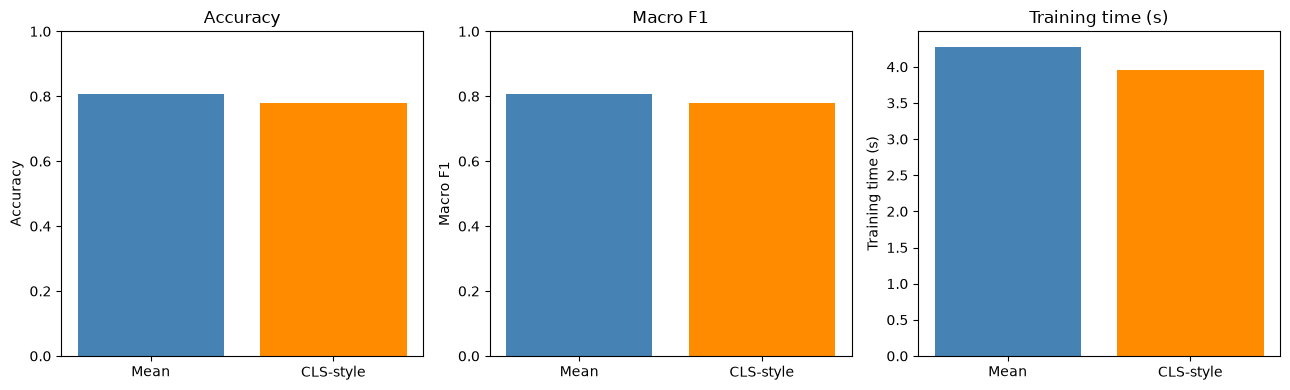

**Cách lấy sequence representation có ảnh hưởng tới classification không?** Ở seed 42, Mean có accuracy=0.8071, macro F1=0.8069; CLS-style có accuracy=0.7799, macro F1=0.7797. Chênh lệch CLS-style − Mean là -0.0272 accuracy và -0.0271 F1. Thời gian tương ứng 4.28s và 3.95s (bao gồm validation). Đây là ảnh hưởng quan sát được trong thiết kế và lần chạy này.

Mean tổng hợp trực tiếp hidden states của token nội dung hợp lệ; CLS-style học cách tập hợp thông tin vào vị trí [CLS] qua self-attention. Cả hai vẫn có CLS tham gia attention; Mean chỉ loại CLS khỏi bước trung bình cuối. Cùng tham số/khởi tạo giúp kiểm soát so sánh nhưng hai encoder được huấn luyện riêng nên thích nghi khác nhau.

Không mặc định CLS-style tốt hơn Mean. Chỉ một seed và một lần đo thời gian chưa đủ kết luận phương pháp nào luôn vượt trội; chênh lệch còn phụ thuộc dữ liệu, quá trình tối ưu và nhiễu đo.

In [6]:
Path("images").mkdir(parents=True, exist_ok=True)
pool_table = pd.DataFrame([
    {"Pooling":name,"Accuracy":r["test"]["accuracy"],"Macro F1":r["test"]["f1"],
     "Training time (s)":r["training_time"],"Parameters":r["parameters"],
     "Macro Precision":r["test"]["precision"],"Macro Recall":r["test"]["recall"],"Best epoch":r["best_epoch"]}
    for name,r in pool_results.items()])
display(pool_table[["Pooling","Accuracy","Macro F1","Training time (s)"]])
display(pool_table[["Pooling","Parameters","Best epoch"]])
pool_table.to_csv(POOL_DIR/"pooling_results.csv",index=False)
fig,axes = plt.subplots(1,3,figsize=(13,4))
for ax,column in zip(axes,["Accuracy","Macro F1","Training time (s)"]):
    ax.bar(pool_table["Pooling"],pool_table[column],color=["steelblue","darkorange"])
    ax.set(ylabel=column,title=column)
    if column in ["Accuracy","Macro F1"]: ax.set_ylim(0,1)
plt.tight_layout(); plt.savefig(Path("images")/"pooling_comparison.png",dpi=150,bbox_inches="tight"); plt.show()
pool_mean,pool_cls = pool_results["Mean"],pool_results["CLS-style"]
display(Markdown(
    "**Cách lấy sequence representation có ảnh hưởng tới classification không?** "
    f"Ở seed 42, Mean có accuracy={pool_mean['test']['accuracy']:.4f}, macro F1={pool_mean['test']['f1']:.4f}; "
    f"CLS-style có accuracy={pool_cls['test']['accuracy']:.4f}, macro F1={pool_cls['test']['f1']:.4f}. "
    f"Chênh lệch CLS-style − Mean là {pool_cls['test']['accuracy']-pool_mean['test']['accuracy']:+.4f} accuracy "
    f"và {pool_cls['test']['f1']-pool_mean['test']['f1']:+.4f} F1. "
    f"Thời gian tương ứng {pool_mean['training_time']:.2f}s và {pool_cls['training_time']:.2f}s "
    "(bao gồm validation). Đây là ảnh hưởng quan sát được trong thiết kế và lần chạy này.\n\n"
    "Mean tổng hợp trực tiếp hidden states của token nội dung hợp lệ; CLS-style học cách tập hợp "
    "thông tin vào vị trí [CLS] qua self-attention. Cả hai vẫn có CLS tham gia attention; Mean chỉ "
    "loại CLS khỏi bước trung bình cuối. Cùng tham số/khởi tạo giúp kiểm soát so sánh nhưng hai encoder "
    "được huấn luyện riêng nên thích nghi khác nhau.\n\n"
    "Không mặc định CLS-style tốt hơn Mean. Chỉ một seed và một lần đo thời gian chưa đủ kết luận "
    "phương pháp nào luôn vượt trội; chênh lệch còn phụ thuộc dữ liệu, quá trình tối ưu và nhiễu đo."
))
